# 17 — Loss functions

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–16, especially likelihood and cross-entropy (04), MSE as Gaussian NLL (06), BCE with logits (09), softmax cross-entropy and log-softmax (10), and MLPs built with `nn.Module` (13–15) |
| **You will learn** | The recipe "choose a distribution for the target, minimize its average negative log-likelihood"; Huber and smooth L1 losses and their bounded gradient; a network that predicts its own noise level with the Gaussian NLL; every detail of `F.cross_entropy`'s interface (extra dimensions, `ignore_index`, class weights, label smoothing, soft targets); multilabel classification with independent sigmoids and `pos_weight`; how `mean`/`sum`/`none` reductions scale gradients, and what "mean" divides by; the error messages produced by wrong inputs; why we train on a loss but report a metric |
| **Estimated time** | About 2.5 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, well under a minute. No GPU section: every model here is small, and nothing about losses changes on a GPU. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math
import warnings

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_blobs, make_spirals
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

f64 = torch.float64

## The motivating problem

A network maps inputs to numbers. The **loss** decides what those numbers mean. The same final `nn.Linear(32, 3)` layer can predict three real-valued quantities, the logits of a 3-class classifier, or three independent yes/no tags — the architecture is identical, and only the loss tells the network which task it is solving. Choosing a loss *is* defining the task.

And the loss is where many of the quietest bugs live. Here are four calls. Each one runs without an error. Which of them compute what their author intended?

In [3]:
set_seed(0)
logits = torch.randn(4, 3)                         # (N, K) = (4, 3): scores from some 3-class model
labels = torch.tensor([0, 2, 1, 2])                # (N,) int64 class indices
tags = torch.tensor([[1., 0., 1.], [0., 0., 0.], [1., 1., 1.], [0., 1., 0.]])   # (N, K) multi-hot: several tags may be on

print("a) F.nll_loss(logits, labels)                 =", round(F.nll_loss(logits, labels).item(), 4))
print("b) F.cross_entropy(logits, tags)              =", round(F.cross_entropy(logits, tags).item(), 4))
print("c) F.cross_entropy(logits, labels, 'sum')     =", round(F.cross_entropy(logits, labels, reduction="sum").item(), 4))
seq_logits = torch.randn(2, 3, 3)                  # (N, T, K): 2 sequences of T = 3 tokens, K = 3 classes per token
seq_labels = torch.tensor([[0, 2, 1], [1, 1, 0]])  # (N, T)
print("d) F.cross_entropy(seq_logits, seq_labels)    =", round(F.cross_entropy(seq_logits, seq_labels).item(), 4))

a) F.nll_loss(logits, labels)                 = -0.2906
b) F.cross_entropy(logits, tags)              = 2.347
c) F.cross_entropy(logits, labels, 'sum')     = 3.7427
d) F.cross_entropy(seq_logits, seq_labels)    = 1.3868


None of them raises an error, and none of them is right for its purpose: (a) treats raw logits as log-probabilities and can even return a *negative* "loss"; (b) treats several on-tags as a probability distribution over mutually exclusive classes; (c) is fine in itself but makes the gradient — and so the effective learning rate — grow with the batch size; (d) reads the wrong dimension as the class dimension. By the end of this notebook you will be able to say exactly what each computes and how to fix it.

**The question: given a type of target, which loss should you use, what exactly must you feed it, and what exactly does it return?**

We organize the answer by target type, building on notebooks 04, 06, 09 and 10 rather than repeating them.

## 1. The recipe: a distribution for the target, then its negative log-likelihood

A quick recap of what Chapters 1–2 established:

- **MSE** is the negative log-likelihood (NLL) of Gaussian noise with a fixed variance (notebooks 04 and 06).
- **MAE** is the NLL of Laplace noise, and it is robust to outliers because each example's gradient is bounded (Chapter 1 problem set; notebook 06, Exercise 4).
- **Binary cross-entropy** is the Bernoulli NLL; computed from logits as $\max(z, 0) - yz + \ln(1 + e^{-|z|})$ it is stable for any $z$ (notebook 09).
- **Categorical cross-entropy** is the categorical NLL; computed with log-softmax it is stable, and at a small initialization it is $\approx \ln K$ (notebook 10).

These are four instances of one recipe. The network outputs some numbers $\mathbf o = f_\theta(\mathbf x)$. We **choose a probability distribution** $p(y \mid \mathbf o)$ for the target, whose parameters are computed from $\mathbf o$, and we minimize the average NLL

$$L(\theta) = \frac1N\sum_{i=1}^N -\ln p\big(y_i \mid f_\theta(\mathbf x_i)\big).$$

The outputs are always **unconstrained real numbers** (logits, or raw scores); the loss function itself maps them to valid distribution parameters (a probability via sigmoid or softmax, a positive variance via $\exp$), inside a numerically stable formula. The table summarizes the cases in this notebook.

| Target | Distribution $p(y \mid \mathbf o)$ | Loss | PyTorch | Model outputs, shape | Target dtype, shape |
| --- | --- | --- | --- | --- | --- |
| real value | Gaussian, fixed $\sigma$ | MSE | `F.mse_loss(pred, y)` | mean $\hat y$, `(N,)` or `(N, D)` | float, **same shape** |
| real value with outliers | Laplace | MAE | `F.l1_loss(pred, y)` | location, `(N,)` | float, same shape |
| real value, robust and smooth | density $\propto e^{-\text{huber}(r)}$ | Huber | `F.huber_loss(pred, y, delta=δ)` | location, `(N,)` | float, same shape |
| real value, noise varies with $\mathbf x$ | Gaussian, predicted $\sigma^2(\mathbf x)$ | Gaussian NLL | `F.gaussian_nll_loss(mu, y, var)` | mean and $\ln\sigma^2$, `(N,)` each | float, same shape |
| count $0, 1, 2, \ldots$ | Poisson | Poisson NLL | `F.poisson_nll_loss(log_rate, y)` | $\ln\lambda$, `(N,)` | float, same shape |
| one of 2 classes | Bernoulli | BCE | `F.binary_cross_entropy_with_logits(z, y)` | logit, `(N,)` | float in $\{0, 1\}$, same shape |
| one of $K$ classes | categorical | cross-entropy | `F.cross_entropy(Z, y)` | logits, `(N, K)` | **int64**, `(N,)` (or float probabilities `(N, K)`) |
| any subset of $K$ labels | $K$ independent Bernoullis | BCE per label | `F.binary_cross_entropy_with_logits(Z, Y)` | logits, `(N, K)` | float multi-hot, `(N, K)` |

Each `F.*` function has a module twin (`nn.MSELoss`, `nn.CrossEntropyLoss`, `nn.BCEWithLogitsLoss`, …) that stores the options and computes the same thing.

### The recipe on a new distribution: counts

To see the recipe work on a target we have not met, take **counts** — the number of clicks, arrivals, or photons, $y \in \{0, 1, 2, \ldots\}$. The standard model is the **Poisson** distribution with rate $\lambda > 0$:

$$p(y \mid \lambda) = \frac{\lambda^y e^{-\lambda}}{y!}, \qquad -\ln p(y \mid \lambda) = \lambda - y\ln\lambda + \ln y!.$$

The rate must be positive, so the network outputs $s = \ln\lambda$ (any real number) and $\lambda = e^s$. The NLL is then $e^s - ys + \ln y!$. The last term does not depend on the model, so it can be dropped for training. Its gradient is $\partial\ell/\partial s = e^s - y = \lambda - y$: once again "prediction minus target", as for MSE, BCE and cross-entropy. `F.poisson_nll_loss(s, y)` computes $e^s - ys$ (with the default `log_input=True` it takes $s = \ln\lambda$; `full=True` adds an approximation of $\ln y!$).

In [4]:
s_demo = torch.tensor([0.0, 1.0, -2.0, 2.5], dtype=f64, requires_grad=True)   # (4,) log-rates
y_counts = torch.tensor([1.0, 4.0, 0.0, 10.0], dtype=f64)                       # (4,) observed counts
manual = (torch.exp(s_demo) - y_counts * s_demo).mean()
print("manual  e^s - y s, averaged :", manual.item())
print("F.poisson_nll_loss          :", F.poisson_nll_loss(s_demo, y_counts).item())
exact = -torch.distributions.Poisson(torch.exp(s_demo)).log_prob(y_counts).mean()
print("exact NLL (with ln y!)      :", exact.item(), "  difference = mean ln y! =", (torch.lgamma(y_counts + 1)).mean().item())
manual.backward()
print("gradient * N                :", (s_demo.grad * 4).tolist())
print("λ - y                       :", (torch.exp(s_demo) - y_counts).tolist())

manual  e^s - y s, averaged : -3.2409722319002174
F.poisson_nll_loss          : -3.2409722319002174
exact NLL (with ln y!)      : 1.3296443689556483   difference = mean ln y! = 4.570616600855866
gradient * N                : [0.0, -1.281718171540955, 0.1353352832366127, 2.1824939607034732]
λ - y                       : [0.0, -1.281718171540955, 0.1353352832366127, 2.1824939607034732]


The manual formula and PyTorch agree; they differ from the exact NLL only by the constant $\frac1N\sum_i\ln y_i!$, and the gradient (times $N$, undoing the mean) is $\lambda - y$.

### Checkpoint 1.1

A Poisson model outputs $\lambda$ **directly** (already positive, for example through a softplus) rather than $\ln\lambda$. `F.poisson_nll_loss` handles this with `log_input=False`, where it computes $\lambda - y\ln(\lambda + \epsilon)$ with a small $\epsilon = 10^{-8}$ that avoids $\ln 0$. Write `poisson_nll_rate(lam, y)` returning the mean of $\lambda - y\ln(\lambda + 10^{-8})$ over all elements, for `lam` and `y` of the same shape.

<details>
<summary><b>💡 Hint</b></summary>

One line: `(lam - y * torch.log(lam + 1e-8)).mean()`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_lam = torch.tensor([0.5, 2.0, 7.0, 1e-3, 3.0])
_y = torch.tensor([0.0, 3.0, 5.0, 1.0, 3.0])
check_close(poisson_nll_rate(_lam, _y), F.poisson_nll_loss(_lam, _y, log_input=False), "poisson_nll_rate")
check_close(poisson_nll_rate(_lam[:2], _y[:2]), F.poisson_nll_loss(_lam[:2], _y[:2], log_input=False), "poisson_nll_rate on 2 elements")
passed("Checkpoint 1.1")

## 2. Regression beyond MSE

### Huber loss: quadratic near zero, linear far away

MSE punishes a residual $r = \hat y - y$ by $r^2$, so its gradient $2r$ grows without bound and a few outliers can dominate a fit. MAE's gradient $\operatorname{sign}(r)$ is bounded, but it never shrinks near the optimum and $|r|$ has a kink at 0, so gradient descent with a fixed step jitters (notebook 06, Exercise 4). The **Huber loss** (Huber, 1964) takes the best of both: with a threshold $\delta > 0$,

$$\operatorname{huber}_\delta(r) = \begin{cases} \tfrac12 r^2 & |r| \le \delta, \\ \delta\big(|r| - \tfrac12\delta\big) & |r| > \delta. \end{cases}$$

The two pieces meet at $|r| = \delta$ with the same value ($\tfrac12\delta^2$) and the same slope. Differentiate each piece:

$$\frac{d}{dr}\operatorname{huber}_\delta(r) = \begin{cases} r & |r| \le \delta, \\ \delta\,\operatorname{sign}(r) & |r| > \delta, \end{cases} \qquad\text{that is,}\qquad \frac{d}{dr}\operatorname{huber}_\delta(r) = \operatorname{clamp}(r, -\delta, \delta).$$

So the gradient is MSE-like (proportional to the residual, shrinking to 0 at the optimum) for small residuals, and **bounded by $\delta$** for large ones: an outlier can push no harder than $\delta$. The derivative is continuous, so there is no kink. As $\delta \to \infty$ Huber becomes $\frac12 r^2$; as $\delta \to 0$, $\operatorname{huber}_\delta / \delta \to |r|$.

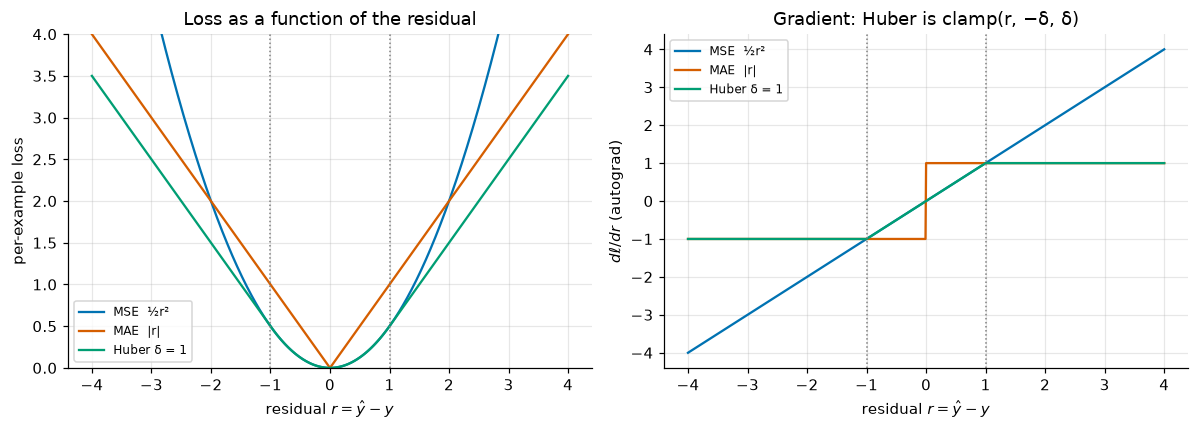

max |autograd Huber gradient - clamp(r, -1, 1)| = 0.0


In [7]:
r = torch.linspace(-4, 4, 801, requires_grad=True)          # (801,) residuals
zeros = torch.zeros(801)
curves = {"MSE  ½r²": 0.5 * r ** 2, "MAE  |r|": r.abs(), "Huber δ = 1": F.huber_loss(r, zeros, delta=1.0, reduction="none")}
grads = {name: torch.autograd.grad(v.sum(), r)[0] for name, v in curves.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for k, (name, v) in enumerate(curves.items()):
    ax1.plot(r.detach(), v.detach(), color=COLORS[k], label=name)
    ax2.plot(r.detach(), grads[name], color=COLORS[k], label=name)
for ax in (ax1, ax2):
    ax.axvline(-1, color="gray", ls=":", lw=1)
    ax.axvline(1, color="gray", ls=":", lw=1)
    ax.set_xlabel("residual $r = \\hat y - y$")
    ax.legend(fontsize=8)
ax1.set_ylim(0, 4)
ax1.set_ylabel("per-example loss")
ax1.set_title("Loss as a function of the residual")
ax2.set_ylabel("$d\\ell / dr$ (autograd)")
ax2.set_title("Gradient: Huber is clamp(r, −δ, δ)")
plt.tight_layout()
plt.show()
print("max |autograd Huber gradient - clamp(r, -1, 1)| =", (grads["Huber δ = 1"] - r.detach().clamp(-1, 1)).abs().max().item())

Left: Huber coincides with $\frac12 r^2$ inside the dotted lines $|r| \le \delta$ and grows linearly outside, parallel to $|r|$. Right: its gradient follows MSE's straight line in the middle and then flattens at $\pm\delta$, exactly the clamp derived above (the printed difference is 0).

### `F.huber_loss` versus `F.smooth_l1_loss`

PyTorch has a second, older function, `F.smooth_l1_loss(pred, y, beta=β)`, popularized by object detectors (Girshick, *Fast R-CNN*, 2015). It is defined as $\frac{1}{2\beta}r^2$ for $|r| < \beta$ and $|r| - \frac12\beta$ otherwise. Divide the Huber loss by $\delta$: $\frac{1}{2\delta}r^2$ inside and $|r| - \frac12\delta$ outside. So

$$\operatorname{smooth\_l1}_\beta(r) = \frac{\operatorname{huber}_\beta(r)}{\beta}.$$

Same shape, different scale: smooth L1's linear part always has slope 1 (like MAE), Huber's has slope $\delta$ (like MSE's gradient at the threshold). For $\delta = \beta = 1$ they are identical.

In [8]:
r_test = torch.linspace(-5, 5, 1001)
for d in [0.1, 0.5, 1.0, 3.0]:
    h = F.huber_loss(r_test, torch.zeros_like(r_test), delta=d, reduction="none")
    s = F.smooth_l1_loss(r_test, torch.zeros_like(r_test), beta=d, reduction="none")
    print(f"δ = β = {d:3}: max |smooth_l1 - huber/δ| = {(s - h / d).abs().max().item():.2e}")

δ = β = 0.1: max |smooth_l1 - huber/δ| = 2.38e-07
δ = β = 0.5: max |smooth_l1 - huber/δ| = 0.00e+00
δ = β = 1.0: max |smooth_l1 - huber/δ| = 0.00e+00
δ = β = 3.0: max |smooth_l1 - huber/δ| = 2.38e-07


The identity holds to `float32` rounding for every $\delta$. The practical consequence: switching between the two with the same threshold changes the loss scale by $1/\delta$, and hence (for SGD) the effective learning rate — Section 5 makes this precise. Exercise 1 explores what $\delta$ does to a fit with outliers.

### Checkpoint 2.1

Write `huber_grad(r, delta)` returning $\frac{d}{dr}\operatorname{huber}_\delta(r)$ elementwise for a tensor of residuals, **without** autograd and without `clamp` — use `torch.where` on the two cases of the derivation.

<details>
<summary><b>💡 Hint</b></summary>

`torch.where(r.abs() <= delta, r, delta * torch.sign(r))`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_r = torch.tensor([-7.0, -2.0, -0.5, 0.0, 0.3, 1.9, 2.1, 40.0], dtype=f64, requires_grad=True)
for _d in [0.5, 2.0]:
    _g = torch.autograd.grad(F.huber_loss(_r, torch.zeros_like(_r), delta=_d, reduction="sum"), _r)[0]
    check_close(huber_grad(_r.detach(), _d), _g, f"huber_grad with delta = {_d}")
passed("Checkpoint 2.1")

### When the noise level depends on the input

MSE assumes every target has the same noise variance $\sigma^2$. Often the noise varies: measurements are less precise at some inputs than at others (**heteroscedastic** noise). The recipe handles this directly: let the network output **two** numbers per input, a mean $\mu(\mathbf x)$ and a log-variance $v(\mathbf x) = \ln\sigma^2(\mathbf x)$, and use the Gaussian NLL with *both* parameters predicted:

$$\ell = -\ln \mathcal N\big(y \mid \mu, \sigma^2\big) = \frac12\left(\ln\sigma^2 + \frac{(y - \mu)^2}{\sigma^2}\right) + \frac12\ln 2\pi.$$

(Nix and Weigend, 1994, trained networks this way.) We predict $\ln\sigma^2$, not $\sigma^2$, because a network output can be any real number while a variance must be positive; $\sigma^2 = e^{v}$ is always positive.

**What does the loss ask the variance to be?** Hold the residual $r = y - \mu$ fixed and differentiate with respect to $v = \ln\sigma^2$, using $1/\sigma^2 = e^{-v}$:

$$\frac{\partial\ell}{\partial v} = \frac12\big(1 - r^2 e^{-v}\big) = 0 \iff \sigma^2 = r^2.$$

Averaged over many examples near the same $\mathbf x$, the best $\sigma^2(\mathbf x)$ is the average squared residual there — the local noise variance. The two terms pull against each other: $\frac{r^2}{\sigma^2}$ punishes claiming too little noise, $\ln\sigma^2$ punishes claiming too much. And the mean's gradient, $\partial\ell/\partial\mu = -r/\sigma^2$, is down-weighted where the predicted noise is large: noisy regions influence the mean less.

`F.gaussian_nll_loss(mu, y, var)` computes $\frac12(\ln \text{var} + (y - \mu)^2/\text{var})$, averaged, with the constant only if `full=True`, and it clamps `var` below at `eps = 1e-6` for stability.

In [11]:
mu_t = torch.tensor([0.0, 1.0, -2.0], dtype=f64)
y_t = torch.tensor([0.5, 3.0, -2.0], dtype=f64)
var_t = torch.tensor([1.0, 4.0, 0.25], dtype=f64)
manual = (0.5 * (torch.log(var_t) + (y_t - mu_t) ** 2 / var_t)).mean()
print("manual                       :", manual.item())
print("F.gaussian_nll_loss          :", F.gaussian_nll_loss(mu_t, y_t, var_t).item())
print("full=True vs exact log-density:", F.gaussian_nll_loss(mu_t, y_t, var_t, full=True).item(),
      -torch.distributions.Normal(mu_t, var_t.sqrt()).log_prob(y_t).mean().item())

manual                       : 0.20833333333333337
F.gaussian_nll_loss          : 0.20833333333333337
full=True vs exact log-density: 1.127271866538006 1.127271866538006


The formula matches, and with `full=True` it is exactly the Gaussian negative log-density. Now a 1-D task with input-dependent noise: $x$ uniform on $[-3, 3]$, $y = \sin x + \sigma(x)\,\varepsilon$ with $\varepsilon \sim \mathcal N(0, 1)$ and a noise level that rises from about 0.1 on the left to 0.5 on the right, $\sigma(x) = 0.1 + 0.4\,\operatorname{sigmoid}(2x)$. (Small regression datasets like this one are generated in the notebook, as in notebooks 06 and 12.)

In [12]:
def true_sigma(x):
    return 0.1 + 0.4 * torch.sigmoid(2 * x)


gen = torch.Generator().manual_seed(0)
N_het = 1000
x_het = 6 * torch.rand(N_het, 1, generator=gen) - 3                         # (N, 1) inputs
y_het = torch.sin(x_het) + true_sigma(x_het) * torch.randn(N_het, 1, generator=gen)   # (N, 1) targets


def make_regressor(n_out, seed):
    """A 1 -> 64 -> 64 -> n_out tanh MLP."""
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, n_out))


het_net = make_regressor(2, seed=0)                    # outputs (mean, log-variance)
mse_net = make_regressor(1, seed=0)                    # outputs the mean only
opt_het = torch.optim.Adam(het_net.parameters(), lr=3e-3)   # Adam: a variant of gradient descent, notebook 19
opt_mse = torch.optim.Adam(mse_net.parameters(), lr=3e-3)
for step in range(2000):
    out = het_net(x_het)                               # (N, 2)
    mu, log_var = out[:, :1], out[:, 1:]               # (N, 1) each — same shape as y_het
    loss_het = F.gaussian_nll_loss(mu, y_het, log_var.exp())
    opt_het.zero_grad()
    loss_het.backward()
    opt_het.step()

    loss_mse = F.mse_loss(mse_net(x_het), y_het)
    opt_mse.zero_grad()
    loss_mse.backward()
    opt_mse.step()
print(f"final Gaussian NLL {loss_het.item():.4f}, final MSE of the mean-only network {loss_mse.item():.4f}")

final Gaussian NLL -0.9286, final MSE of the mean-only network 0.1123


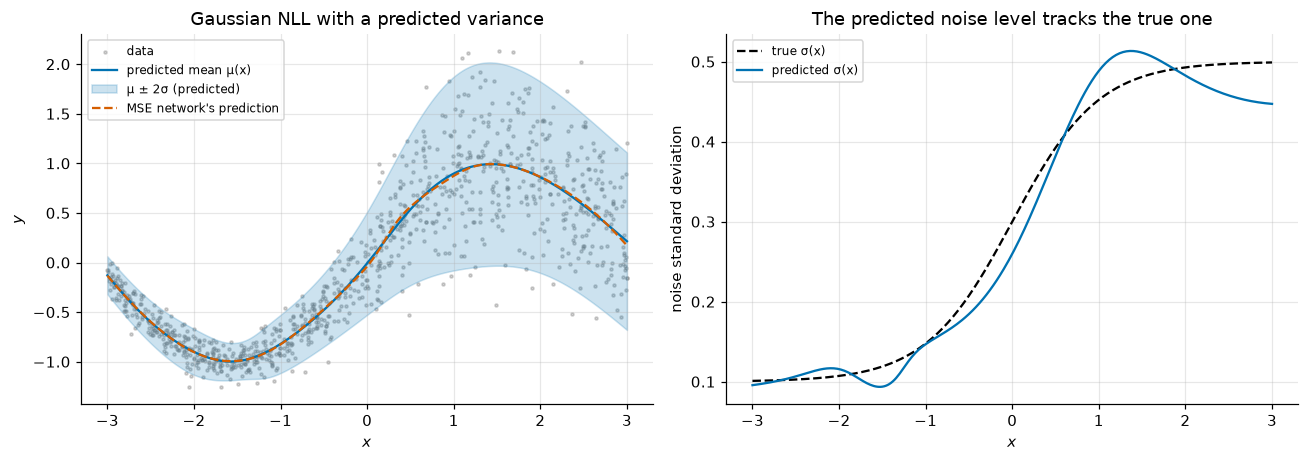

max |predicted σ - true σ| on [-2.9, 2.9]: 0.050
max |μ - sin x| (NLL network): 0.073, (MSE network): 0.085


In [13]:
x_grid = torch.linspace(-3, 3, 301)[:, None]           # (301, 1)
with torch.no_grad():
    out = het_net(x_grid)
    mu_g, sigma_g = out[:, 0], (0.5 * out[:, 1]).exp()  # σ = exp(½ ln σ²)
    mse_g = mse_net(x_grid)[:, 0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.scatter(x_het[:, 0], y_het[:, 0], s=4, alpha=0.35, color="gray", label="data")
ax1.plot(x_grid[:, 0], mu_g, color=COLORS[0], label="predicted mean μ(x)")
ax1.fill_between(x_grid[:, 0], mu_g - 2 * sigma_g, mu_g + 2 * sigma_g, color=COLORS[0], alpha=0.2, label="μ ± 2σ (predicted)")
ax1.plot(x_grid[:, 0], mse_g, color=COLORS[1], ls="--", label="MSE network's prediction")
ax1.set_xlabel("$x$")
ax1.set_ylabel("$y$")
ax1.set_title("Gaussian NLL with a predicted variance")
ax1.legend(fontsize=8, loc="upper left")
ax2.plot(x_grid[:, 0], true_sigma(x_grid[:, 0]), color="k", ls="--", label="true σ(x)")
ax2.plot(x_grid[:, 0], sigma_g, color=COLORS[0], label="predicted σ(x)")
ax2.set_xlabel("$x$")
ax2.set_ylabel("noise standard deviation")
ax2.set_title("The predicted noise level tracks the true one")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

with torch.no_grad():
    mid = x_grid[:, 0].abs() < 2.9
    print(f"max |predicted σ - true σ| on [-2.9, 2.9]: {(sigma_g - true_sigma(x_grid[:, 0]))[mid].abs().max().item():.3f}")
    print(f"max |μ - sin x| (NLL network): {(mu_g - torch.sin(x_grid[:, 0])).abs().max().item():.3f}, "
          f"(MSE network): {(mse_g - torch.sin(x_grid[:, 0])).abs().max().item():.3f}")

Left: the band $\mu \pm 2\sigma$ is narrow where the data are tight and wide where they scatter, and both networks' means follow $\sin x$ about equally well (largest errors 0.07 and 0.09). Right: the predicted $\sigma(x)$ follows the true noise level across the range, within 0.05 everywhere on $[-2.9, 2.9]$ — it is estimated from only 1000 noisy points. The MSE network gives a mean too, but no statement about how far to trust it.

Two cautions, stated without proof. The loss can be lowered without limit by shrinking $\sigma^2$ on points the mean fits exactly, which is one reason for the `eps` clamp; and with a flexible network the variance can "explain away" a badly fit mean, so the mean is sometimes learned more slowly than under MSE (Seitzer et al., 2022, analyse this and propose a fix). And note that the NLL value can be **negative**: it is a density, and densities can exceed 1 (notebook 04).

### Checkpoint 2.2

For one example with target $y = 2$, predicted mean $\mu = 0.5$, which variance `best_var` minimizes `F.gaussian_nll_loss`? And what is the loss `best_loss` there (with the default `full=False`)? Work it out by hand from the derivation above, then type in the numbers.

<details>
<summary><b>💡 Hint</b></summary>

The minimizer is $\sigma^2 = r^2$ with $r = y - \mu = 1.5$. At that variance $r^2/\sigma^2 = 1$, so the loss is $\frac12(\ln r^2 + 1)$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
_v = torch.linspace(0.05, 10, 20000, dtype=f64)
_l = F.gaussian_nll_loss(torch.full_like(_v, 0.5), torch.full_like(_v, 2.0), _v, reduction="none")
check_close(best_var, _v[_l.argmin()].item(), "best_var", rtol=0, atol=1e-3)
check_close(best_loss, _l.min().item(), "best_loss", rtol=0, atol=1e-6)
passed("Checkpoint 2.2")

## 3. Multiclass: the details of `F.cross_entropy`

Notebook 10 established the basics: `F.cross_entropy(Z, y)` takes logits `Z` of shape `(N, K)` and integer class indices `y` of dtype `int64` and shape `(N,)`, and computes `F.nll_loss(F.log_softmax(Z, dim=1), y)` stably. This section covers the options you will meet in real code.

### Extra dimensions: the class dimension is dimension 1

Many tasks classify **many things per example**: every pixel of an image (segmentation), every token of a sentence. Then the logits have shape `(N, K, d₁, …)` and the targets `(N, d₁, …)`: the class scores always sit in **dimension 1**, not in the last dimension. Take $N = 2$ sentences of $T = 5$ tokens, each token one of $K = 3$ classes.

In [16]:
set_seed(0)
N_seq, T, K = 2, 5, 3
Z_seq = torch.randn(N_seq, K, T)                        # (N, K, T): class scores in dim 1
y_seq = torch.randint(0, K, (N_seq, T))                 # (N, T) one class index per token
loss_seq = F.cross_entropy(Z_seq, y_seq)
# The same loss, flattening every token into its own row: (N*T, K) logits and (N*T,) targets.
loss_flat = F.cross_entropy(Z_seq.permute(0, 2, 1).reshape(-1, K), y_seq.reshape(-1))
print(f"F.cross_entropy on (N, K, T): {loss_seq.item():.6f}   on flattened (N·T, K): {loss_flat.item():.6f}")

Z_last = Z_seq.permute(0, 2, 1)                         # (N, T, K): the natural layout of most models' outputs
try:
    F.cross_entropy(Z_last, y_seq)
except RuntimeError as err:
    print("logits (N, T, K) with T = 5, K = 3 ->", type(err).__name__ + ":", str(err).splitlines()[0])

F.cross_entropy on (N, K, T): 1.052518   on flattened (N·T, K): 1.052518
logits (N, T, K) with T = 5, K = 3 -> RuntimeError: Expected target size [2, 3], got [2, 5]


The two correct forms agree: the loss is the mean over all $N \cdot T$ tokens. With the classes in the **last** dimension, PyTorch reads `T` as the number of classes and `K` as the sequence length, and the shapes no longer match the targets, so we get an error. But if the two sizes happen to be **equal**, nothing complains:

In [17]:
set_seed(1)
Z_sq = torch.randn(N_seq, 3, 3)                         # (N, T, K) with T = K = 3: the classes are in the LAST dim
y_sq = torch.randint(0, 3, (N_seq, 3))                  # (N, T)
print(f"correct: classes moved to dim 1 : {F.cross_entropy(Z_sq.permute(0, 2, 1), y_sq).item():.4f}")
print(f"wrong:   classes left in dim 2  : {F.cross_entropy(Z_sq, y_sq).item():.4f}   (no error!)")

correct: classes moved to dim 1 : 1.0726
wrong:   classes left in dim 2  : 0.9575   (no error!)


The wrong call normalizes the softmax over the *sequence positions* instead of the classes. It trains — towards a meaningless objective. When the number of classes can equal another dimension, check the layout explicitly, or flatten to `(rows, K)` as above, which is unambiguous.

### `ignore_index`: targets that should not count

Padding tokens, unlabeled pixels: some positions have no valid target. Set their target to a special value, by default `ignore_index = -100`. Those positions contribute nothing, and the mean is taken **over the remaining positions only**:

In [18]:
y_pad = y_seq.clone()
y_pad[1, 3:] = -100                                     # the second sentence has only 3 real tokens
per_token = F.cross_entropy(Z_seq, y_pad, reduction="none")   # (N, T); ignored positions get loss 0
keep = y_pad != -100
print("per-token losses (ignored = 0):\n", per_token)
print(f"F.cross_entropy with ignore_index : {F.cross_entropy(Z_seq, y_pad).item():.6f}")
print(f"sum over kept / number kept ({keep.sum().item()})  : {(per_token.sum() / keep.sum()).item():.6f}")
print(f"if every target is ignored        : {F.cross_entropy(Z_seq, torch.full_like(y_seq, -100)).item()}")

per-token losses (ignored = 0):
 tensor([[0.6274, 1.1939, 0.5864, 1.3781, 2.5120],
        [0.7456, 1.1688, 1.7642, 0.0000, 0.0000]])
F.cross_entropy with ignore_index : 1.247045
sum over kept / number kept (8)  : 1.247046
if every target is ignored        : nan


The ignored positions have zero loss and are excluded from the count: the result divides by 8 kept tokens, not 10. If a batch happens to contain only ignored targets, the mean is $0/0$ = `nan` — worth guarding against in code that can produce such batches.

### Class weights: `weight=`

With `weight=w` (a float tensor of shape `(K,)`), example $i$'s loss is multiplied by $w_{y_i}$, the weight of its **true** class, and the mean becomes a **weighted mean**:

$$L = \frac{\sum_i w_{y_i}\,\ell_i}{\sum_i w_{y_i}}, \qquad \ell_i = -\ln p_{i, y_i}.$$

For integer targets, giving class $k$ weight $w_k$ is the same as having each class-$k$ example appear $w_k$ times in the dataset. To see what that does, take the simplest model: one that ignores the input and predicts the same probabilities $\mathbf p$ for every example. With $n_k$ examples of class $k$, minimizing $-\sum_k w_k n_k\ln p_k$ subject to $\sum_k p_k = 1$ gives (Lagrange multipliers, or notebook 04's categorical MLE with counts $w_k n_k$)

$$p_k^* = \frac{w_k n_k}{\sum_j w_j n_j}.$$

With no weights this is the class frequency. With the common "balanced" choice $w_k \propto 1/n_k$ it is **uniform**: the weighted loss pretends the classes are equally common. We check by fitting only a bias vector (a model that has nothing else) on an imbalanced label set:

In [19]:
counts = torch.tensor([900, 90, 10])                    # (K,) class counts: very imbalanced
y_imb = torch.repeat_interleave(torch.arange(3), counts)   # (1000,) labels
for name, w in [("no weights", None), ("w_k ∝ 1/n_k (balanced)", counts.sum() / (3 * counts.float())),
                ("w = (1, 2, 5)", torch.tensor([1.0, 2.0, 5.0]))]:
    bias = torch.zeros(3, requires_grad=True)           # logits = bias for every example
    opt = torch.optim.LBFGS([bias], max_iter=200, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(bias.expand(len(y_imb), 3), y_imb, weight=w)
        loss.backward()
        return loss

    opt.step(closure)
    wk = torch.ones(3) if w is None else w
    predicted = (wk * counts) / (wk * counts).sum()
    print(f"{name:24s}: fitted p = {[round(v, 4) for v in torch.softmax(bias.detach(), 0).tolist()]}   "
          f"formula w_k n_k / Σ w_j n_j = {[round(v, 4) for v in predicted.tolist()]}")

no weights              : fitted p = [0.9, 0.09, 0.01]   formula w_k n_k / Σ w_j n_j = [0.9, 0.09, 0.01]
w_k ∝ 1/n_k (balanced)  : fitted p = [0.3333, 0.3333, 0.3333]   formula w_k n_k / Σ w_j n_j = [0.3333, 0.3333, 0.3333]
w = (1, 2, 5)           : fitted p = [0.7965, 0.1593, 0.0442]   formula w_k n_k / Σ w_j n_j = [0.7965, 0.1593, 0.0442]


(L-BFGS, used as a black-box minimizer as in notebook 09.) The fitted probabilities match the formula in every case. Weighting therefore does not make the model "better"; it changes **what the model believes the class proportions are**. A weighted classifier systematically over-predicts the up-weighted classes relative to their true frequency. Whether that trade is worth it depends on what errors cost — Exercise 4 measures it on a real decision boundary, and notebook 25 covers thresholds and imbalance properly.

### Label smoothing: `label_smoothing=`

With integer targets the model is rewarded for pushing $p_{y}$ all the way to 1, which needs $z_y - z_k \to \infty$: the logits never stop growing, like logistic regression on separable data (notebook 09, Section 7). **Label smoothing** (Szegedy et al., 2016) replaces the one-hot target by a mixture with the uniform distribution. With smoothing $\varepsilon$, the target for an example of class $y$ is

$$q_k = (1 - \varepsilon)\,[k = y] + \frac{\varepsilon}{K}, \qquad\text{so}\quad q_y = 1 - \varepsilon + \frac{\varepsilon}{K},\quad q_{k \ne y} = \frac{\varepsilon}{K},$$

and the loss is the cross-entropy $H(\mathbf q, \mathbf p) = -\sum_k q_k \ln p_k$. Expanding, $H(\mathbf q, \mathbf p) = (1 - \varepsilon)(-\ln p_y) + \varepsilon\cdot\frac1K\sum_k(-\ln p_k)$: the usual loss plus a penalty on giving any class a tiny probability.

**The minimum is not zero.** Notebook 04 showed $H(\mathbf q, \mathbf p) = H(\mathbf q) + \mathrm{KL}(\mathbf q\,\|\,\mathbf p) \ge H(\mathbf q)$, with equality exactly when $\mathbf p = \mathbf q$. So the best the model can do is predict $\mathbf q$ itself, which needs only **finite** logits, with gap $z_y - z_k = \ln\frac{q_y}{q_k} = \ln\frac{1 - \varepsilon + \varepsilon/K}{\varepsilon/K}$; and the smallest possible loss is the entropy $H(\mathbf q) > 0$. We verify with free logits trained to convergence:

In [20]:
K_ls, eps_ls = 4, 0.1
q_y, q_other = 1 - eps_ls + eps_ls / K_ls, eps_ls / K_ls
H_q = -(q_y * math.log(q_y) + (K_ls - 1) * q_other * math.log(q_other))

z_free = torch.zeros(1, K_ls, dtype=f64, requires_grad=True)     # (1, K) logits of one example of class 0
target0 = torch.tensor([0])
opt = torch.optim.LBFGS([z_free], max_iter=500, tolerance_grad=1e-12, tolerance_change=1e-14, line_search_fn="strong_wolfe")


def closure():
    opt.zero_grad()
    loss = F.cross_entropy(z_free, target0, label_smoothing=eps_ls)
    loss.backward()
    return loss


opt.step(closure)
z_opt = z_free.detach()[0]
print(f"minimum loss found      : {F.cross_entropy(z_free.detach(), target0, label_smoothing=eps_ls).item():.8f}")
print(f"entropy H(q)            : {H_q:.8f}")
print(f"softmax at the optimum  : {[round(v, 6) for v in torch.softmax(z_opt, 0).tolist()]}")
print(f"target q                : {[round(v, 6) for v in [q_y] + [q_other] * (K_ls - 1)]}")
print(f"logit gap z_0 - z_1     : {(z_opt[0] - z_opt[1]).item():.6f}   ln(q_y / q_other) = {math.log(q_y / q_other):.6f}")

minimum loss found      : 0.34878038
entropy H(q)            : 0.34878038
softmax at the optimum  : [0.925, 0.025, 0.025, 0.025]
target q                : [0.925, 0.025, 0.025, 0.025]
logit gap z_0 - z_1     : 3.610918   ln(q_y / q_other) = 3.610918


The optimum predicts exactly $\mathbf q$, the logit gap is the finite value $\ln(0.925/0.025) = \ln 37 \approx 3.61$, and the minimum loss is $H(\mathbf q) \approx 0.349$, not 0. Two practical consequences: a smoothed loss that "won't go below 0.35" is not a bug; and comparing losses between runs with and without smoothing is meaningless. Label smoothing's effect as a **regularizer** — on overconfidence and generalization — is the subject of notebook 23.

### Soft targets: probabilities instead of indices

`F.cross_entropy` also accepts a **float** target of shape `(N, K)`, read as one probability distribution per row (notebook 10 noted this). Label smoothing is one source of such targets; others are averaging the labels of several annotators, or the predictions of another model (distillation). We confirm that `label_smoothing=` is exactly cross-entropy with the smoothed distribution as a soft target:

In [21]:
set_seed(2)
Z_s = torch.randn(6, K_ls)                             # (6, K) logits
y_s = torch.randint(0, K_ls, (6,))                     # (6,) labels
q_soft = (1 - eps_ls) * F.one_hot(y_s, K_ls).float() + eps_ls / K_ls   # (6, K), each row sums to 1
print("label_smoothing=0.1          :", F.cross_entropy(Z_s, y_s, label_smoothing=eps_ls).item())
print("soft target q                :", F.cross_entropy(Z_s, q_soft).item())
print("-(q * log_softmax).sum(1).mean():", -(q_soft * F.log_softmax(Z_s, dim=1)).sum(dim=1).mean().item())

label_smoothing=0.1          : 1.6761493682861328
soft target q                : 1.6761493682861328
-(q * log_softmax).sum(1).mean(): 1.6761492490768433


All three agree. Exercise 2 asks you to implement label smoothing from scratch.

### Checkpoint 3.1

For $K = 10$ classes and $\varepsilon = 0.2$, compute `min_smoothed_loss`, the smallest value `F.cross_entropy(..., label_smoothing=0.2)` can take for one example, and `best_gap`, the logit difference $z_y - z_k$ ($k \ne y$) that achieves it. Use the formulas, not an optimizer.

<details>
<summary><b>💡 Hint</b></summary>

$q_y = 1 - 0.2 + 0.02 = 0.82$ and $q_k = 0.02$ for the nine other classes. The minimum is $H(\mathbf q) = -q_y\ln q_y - 9\,q_k\ln q_k$; the gap is $\ln(q_y / q_k)$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"min_smoothed_loss = {min_smoothed_loss:.4f}, best_gap = {best_gap:.4f}")

In [ ]:
_z = torch.zeros(1, 10)
_z[0, 3] = best_gap
check_close(F.cross_entropy(_z, torch.tensor([3]), label_smoothing=0.2).item(), min_smoothed_loss, "loss at the claimed best gap", rtol=1e-5)
for _g in [best_gap - 0.3, best_gap + 0.3]:          # nearby gaps must be worse
    _z[0, 3] = _g
    check(F.cross_entropy(_z, torch.tensor([3]), label_smoothing=0.2).item() > min_smoothed_loss,
          "min_smoothed_loss should be the minimum over logit gaps")
passed("Checkpoint 3.1")

## 4. Multilabel: $K$ independent yes/no questions

In **multiclass** problems each example has exactly one of $K$ classes. In **multilabel** problems each example can have **any subset** of $K$ labels: a photo can contain a dog *and* a car *and* no person; a news article can be tagged "politics" and "economy". The right model, by the recipe, is $K$ **independent Bernoullis**: label $k$ is on with probability $\sigma(z_k)$, and the NLL is a sum of $K$ binary cross-entropies:

$$\ell_i = \sum_{k=1}^K \Big[-Y_{ik}\ln\sigma(Z_{ik}) - (1 - Y_{ik})\ln\big(1 - \sigma(Z_{ik})\big)\Big].$$

In PyTorch: logits `Z` of shape `(N, K)`, a **float** multi-hot target `Y` of shape `(N, K)`, and `F.binary_cross_entropy_with_logits(Z, Y)`.

**Softmax couples the classes, sigmoids don't.** A softmax output sums to 1, so raising one probability lowers the others: it encodes "exactly one of these". Two labels can never both have probability above $\frac12$, an example with **no** labels cannot be expressed at all, and three labels can never all be above $\frac13$. Sigmoids are $K$ separate numbers in $(0, 1)$, each free to be near 0 or 1.

A synthetic task makes this concrete. Points are uniform in the square $[-1, 1]^2$ with three labels: "right half" ($x_1 > 0$), "upper half" ($x_2 > 0$), and "near the center" ($x_1^2 + x_2^2 < 0.5$). A point can have 0, 1, 2 or 3 of them.

In [24]:
gen = torch.Generator().manual_seed(0)
X_ml = 2 * torch.rand(1200, 2, generator=gen) - 1           # (N, 2)
Y_ml = torch.stack([X_ml[:, 0] > 0, X_ml[:, 1] > 0, (X_ml ** 2).sum(1) < 0.5], dim=1).float()   # (N, 3) multi-hot
n_labels = Y_ml.sum(1).long()                                 # (N,) labels per example
print("number of examples with 0, 1, 2, 3 labels:", torch.bincount(n_labels, minlength=4).tolist())


def make_mlp(n_in, n_out, seed, width=32):
    """A small ReLU MLP: n_in -> width -> width -> n_out."""
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(n_in, width), nn.ReLU(), nn.Linear(width, width), nn.ReLU(), nn.Linear(width, n_out))


def train_full_batch(model, loss_fn, X, steps=1000, lr=1e-2):
    """Full-batch Adam on loss_fn(model(X)). Returns the final loss."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        loss = loss_fn(model(X))
        opt.zero_grad()
        loss.backward()
        opt.step()
    return loss.item()


sig_model = make_mlp(2, 3, seed=0)
print("sigmoids + BCE, final loss:", round(train_full_batch(sig_model, lambda Z: F.binary_cross_entropy_with_logits(Z, Y_ml), X_ml), 4))
# The softmax alternative: normalize each multi-hot row into a distribution (rows with no labels contribute 0 loss).
Y_norm = Y_ml / Y_ml.sum(1, keepdim=True).clamp(min=1)
soft_model = make_mlp(2, 3, seed=0)
print("softmax + cross-entropy, final loss:", round(train_full_batch(soft_model, lambda Z: F.cross_entropy(Z, Y_norm), X_ml), 4))

with torch.no_grad():
    P_sig = torch.sigmoid(sig_model(X_ml))                  # (N, 3) independent probabilities
    P_soft = torch.softmax(soft_model(X_ml), dim=1)         # (N, 3) sums to 1 per row
for name, P in [("sigmoid", P_sig), ("softmax", P_soft)]:
    exact = ((P > 0.5).float() == Y_ml).all(dim=1).float()  # (N,) all three labels right?
    by_count = [f"{exact[n_labels == c].mean().item():.3f}" for c in range(4)]
    print(f"{name}: exact-match accuracy {exact.mean().item():.3f}; by number of true labels 0/1/2/3: {by_count}")

number of examples with 0, 1, 2, 3 labels: [178, 488, 421, 113]


sigmoids + BCE, final loss: 0.0022


softmax + cross-entropy, final loss: 0.3514
sigmoid: exact-match accuracy 0.999; by number of true labels 0/1/2/3: ['0.994', '1.000', '1.000', '1.000']
softmax: exact-match accuracy 0.407; by number of true labels 0/1/2/3: ['0.000', '1.000', '0.000', '0.000']


With a threshold of 0.5 the sigmoid model gets essentially every label set exactly right. The softmax model is right only on single-label examples: it cannot put two probabilities above 0.5, and it cannot say "none". Maybe a different threshold rescues it?

softmax: best exact-match accuracy over thresholds = 0.850 at threshold 0.14


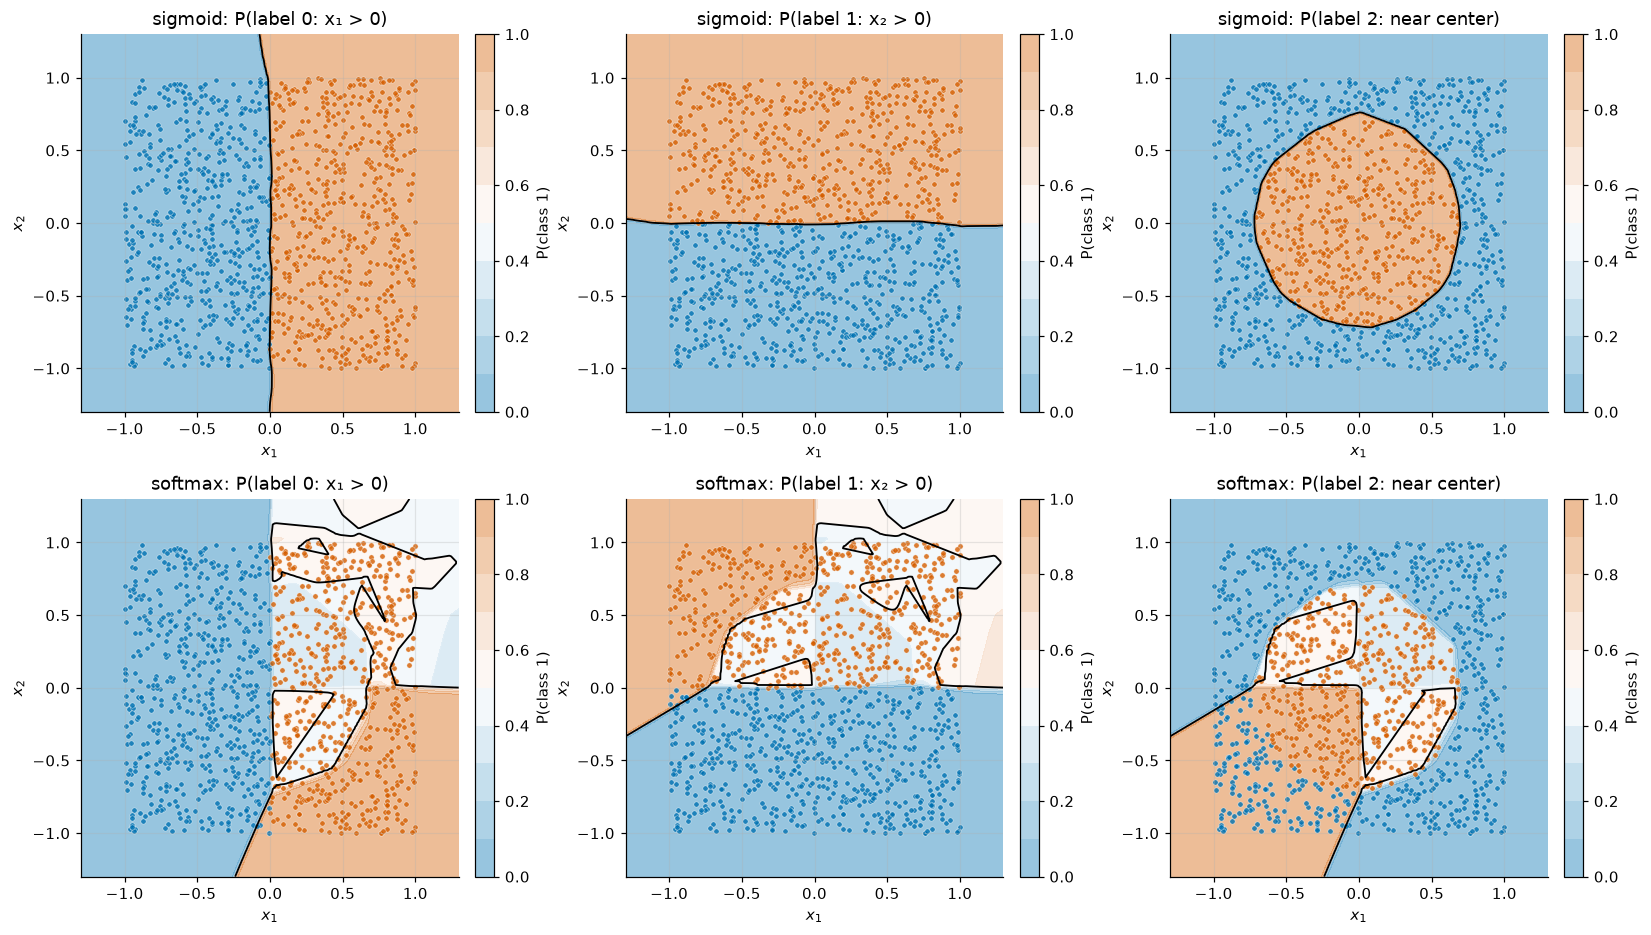

In [25]:
thresholds = torch.linspace(0.05, 0.95, 91)
exact_by_t = torch.stack([((P_soft > t).float() == Y_ml).all(dim=1).float().mean() for t in thresholds])
best = exact_by_t.argmax()
print(f"softmax: best exact-match accuracy over thresholds = {exact_by_t[best].item():.3f} at threshold {thresholds[best].item():.2f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 8.6))
names = ["label 0: x₁ > 0", "label 1: x₂ > 0", "label 2: near center"]
for k in range(3):
    for row, (model, kind) in enumerate([(sig_model, "sigmoid"), (soft_model, "softmax")]):
        fn = (lambda G, m=model, k=k: torch.sigmoid(m(G))[:, k]) if kind == "sigmoid" else (lambda G, m=model, k=k: torch.softmax(m(G), 1)[:, k])
        plot_decision_boundary(fn, X_ml, Y_ml[:, k].long(), ax=axes[row, k], kind="prob", title=f"{kind}: P({names[k]})")
plt.tight_layout()
plt.show()

Top row: each sigmoid output is a clean map of its own label — near 1 on its region, near 0 elsewhere, with the 0.5 contour (black) on the true boundary (the circle comes out as a polygon, as ReLU networks draw it, notebook 12). Bottom row: the softmax outputs have to share one unit of probability, so where two or three labels are on, each gets only about $\frac12$ or $\frac13$ (the pale regions). In the lower-left corner outside the circle, where **no** label is on, the softmax must still put its probability somewhere — here mostly on label 0 or label 2, confidently and wrongly — because those examples gave it no training signal at all. No threshold fixes this: the best one (0.14) reaches exact-match accuracy 0.850, against 0.999 for the sigmoids. The model is not too small — it is the **output distribution** that cannot express the targets.

### Rare labels: `pos_weight`

Multilabel problems often have rare labels (a tag on 1% of examples). `F.binary_cross_entropy_with_logits(Z, Y, pos_weight=p)`, with `p` of shape `(K,)` broadcast over the last dimension, multiplies the **positive** term of label $k$ by $p_k$:

$$\ell_{ik} = -p_k\,Y_{ik}\ln\sigma(Z_{ik}) - (1 - Y_{ik})\ln\big(1 - \sigma(Z_{ik})\big).$$

This is `weight=` again, but per label and only for the positives. As with class weights, a constant predictor shows what it does. If a fraction $\pi$ of examples have the label, the average loss of predicting $\hat p$ everywhere is $-p\,\pi\ln\hat p - (1 - \pi)\ln(1 - \hat p)$; setting its derivative $-\frac{p\pi}{\hat p} + \frac{1 - \pi}{1 - \hat p}$ to zero gives

$$\hat p^* = \frac{p\,\pi}{p\,\pi + 1 - \pi}.$$

With $p = 1$ this is $\pi$, the true frequency; with $p = (1 - \pi)/\pi$ (the number of negatives per positive, a common choice) it is $\frac12$. So `pos_weight` shifts predicted probabilities up — trading more false positives for fewer missed positives.

In [26]:
Z_pw = torch.tensor([[2.0, -1.0], [0.5, -3.0], [-1.0, 0.0]], dtype=f64)   # (N, K) = (3, 2)
Y_pw = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], dtype=f64)
pw = torch.tensor([3.0, 10.0], dtype=f64)                                  # (K,)
manual = (-pw * Y_pw * F.logsigmoid(Z_pw) - (1 - Y_pw) * F.logsigmoid(-Z_pw)).mean()   # log(1 - σ(z)) = logsigmoid(-z)
print("manual formula  :", manual.item())
print("PyTorch         :", F.binary_cross_entropy_with_logits(Z_pw, Y_pw, pos_weight=pw).item())

manual formula  : 7.170875514786464
PyTorch         : 7.170875514786464


The formula matches (note the `.mean()` over **all** $N \cdot K$ entries — Section 5 returns to this).

### Checkpoint 4.1

A label is present in $\pi = 2\%$ of examples. Compute `p_star_3` and `p_star_balanced`, the constant probability that minimizes the loss with `pos_weight = 3` and with `pos_weight` $= (1 - \pi)/\pi$, from the formula above.

<details>
<summary><b>💡 Hint</b></summary>

$\hat p^* = p\pi / (p\pi + 1 - \pi)$. For $p = 3$: $0.06 / (0.06 + 0.98)$. The balanced case should come out to exactly one half.

</details>

In [ ]:
pi_rare = 0.02
# YOUR CODE HERE
raise NotImplementedError
print(f"p* with pos_weight 3: {p_star_3:.4f}; with balanced pos_weight: {p_star_balanced:.4f}")

In [ ]:
def _best_constant(pos_w):
    _y = torch.cat([torch.ones(2), torch.zeros(98)])           # π = 2%
    _zs = torch.linspace(-8, 8, 160001, dtype=f64)
    _losses = torch.stack([F.binary_cross_entropy_with_logits(_zs, torch.full_like(_zs, v), pos_weight=torch.tensor(pos_w, dtype=f64), reduction="none")
                           for v in _y.tolist()]).mean(0)
    return torch.sigmoid(_zs[_losses.argmin()]).item()


check_close(p_star_3, _best_constant(3.0), "p_star_3", rtol=0, atol=1e-4)
check_close(p_star_balanced, _best_constant(49.0), "p_star_balanced", rtol=0, atol=1e-4)
passed("Checkpoint 4.1")

## 5. Reductions: what "the loss" averages over

Every PyTorch loss takes `reduction=`:

- `"mean"` (the default) returns the average of the per-element losses;
- `"sum"` returns their sum;
- `"none"` returns the per-element losses themselves, one per example (or per element), for you to combine.

In [29]:
set_seed(3)
Z_r = torch.randn(8, 4)                                 # (N, K)
y_r = torch.randint(0, 4, (8,))                         # (N,)
none = F.cross_entropy(Z_r, y_r, reduction="none")      # (N,)
print("none :", none.shape, [round(v, 3) for v in none.tolist()])
print(f"mean : {F.cross_entropy(Z_r, y_r).item():.6f} = none.mean() {none.mean().item():.6f}")
print(f"sum  : {F.cross_entropy(Z_r, y_r, reduction='sum').item():.6f} = none.sum()  {none.sum().item():.6f}")

none : torch.Size([8]) [1.435, 2.36, 1.549, 1.373, 0.601, 0.815, 1.026, 2.35]
mean : 1.438782 = none.mean() 1.438782
sum  : 11.510254 = none.sum()  11.510255


### The reduction scales the gradient, so it scales the learning rate

Since $L_{\text{sum}} = N\cdot L_{\text{mean}}$, every gradient is $N$ times larger: $\nabla L_{\text{sum}} = N\,\nabla L_{\text{mean}}$. An SGD step $-\eta\nabla L_{\text{sum}}$ is the step $-(\eta N)\nabla L_{\text{mean}}$. So **SGD with `sum` and learning rate $\eta$ is exactly SGD with `mean` and learning rate $\eta N$**: the effective learning rate grows with the batch size. Change the batch size and a `sum`-reduced run silently changes its step size; that is why `mean` is the default and the convention in this course. We verify both claims on a small MLP:

In [30]:
X_red, y_red = make_spirals(n=50, classes=3, seed=0)    # (150, 2), (150,)
N_red = len(X_red)


def sgd_run(reduction, lr, steps=50, optimizer="sgd"):
    model = make_mlp(2, 3, seed=0, width=16)
    opt = torch.optim.SGD(model.parameters(), lr=lr) if optimizer == "sgd" else torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        loss = F.cross_entropy(model(X_red), y_red, reduction=reduction)
        opt.zero_grad()
        loss.backward()
        opt.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


m0 = make_mlp(2, 3, seed=0, width=16)
g_mean = torch.autograd.grad(F.cross_entropy(m0(X_red), y_red), m0[0].weight)[0]
g_sum = torch.autograd.grad(F.cross_entropy(m0(X_red), y_red, reduction="sum"), m0[0].weight)[0]
print(f"first-layer gradient: max |grad_sum - N·grad_mean| = {(g_sum - N_red * g_mean).abs().max().item():.2e}  (N = {N_red})")

theta_mean = sgd_run("mean", lr=0.5)
theta_sum = sgd_run("sum", lr=0.5 / N_red)
theta_sum_same_lr = sgd_run("sum", lr=0.5)
print(f"SGD, 50 steps: mean (η = 0.5) vs sum (η = 0.5/N): max parameter difference {(theta_mean - theta_sum).abs().max().item():.2e}")
print(f"SGD, 50 steps: mean (η = 0.5) vs sum (η = 0.5):   max parameter difference {(theta_mean - theta_sum_same_lr).abs().max().item():.2e}, "
      f"any non-finite: {not bool(torch.isfinite(theta_sum_same_lr).all())}")
theta_adam_mean = sgd_run("mean", lr=1e-2, optimizer="adam")
theta_adam_sum = sgd_run("sum", lr=1e-2, optimizer="adam")
print(f"Adam, 50 steps, same η: mean vs sum: max parameter difference {(theta_adam_mean - theta_adam_sum).abs().max().item():.2e}")

first-layer gradient: max |grad_sum - N·grad_mean| = 2.38e-07  (N = 150)
SGD, 50 steps: mean (η = 0.5) vs sum (η = 0.5/N): max parameter difference 1.79e-07
SGD, 50 steps: mean (η = 0.5) vs sum (η = 0.5):   max parameter difference 3.39e+04, any non-finite: False
Adam, 50 steps, same η: mean vs sum: max parameter difference 3.14e-03


The `sum` gradient is exactly $N = 150$ times the `mean` gradient, and the two SGD runs coincide to `float32` rounding once the learning rate is divided by $N$. With the *same* learning rate, the `sum` run takes 150-times-larger steps and ends somewhere completely different. Adam, by contrast, is almost unaffected: it divides each step by a running estimate of the gradient's size, which cancels a constant factor up to its small $\epsilon$ term (notebook 19 derives this). So the reduction matters a great deal for SGD and very little for Adam — one more reason a learning rate is only meaningful together with its optimizer and its loss.

### `reduction="none"`: per-example weights and masks

With per-example losses in hand you can combine them however the task requires. A common case is a batch of **sequences of different lengths**, padded to a common length $T$, with a mask $M$ of shape `(N, T)` that is 1 on real tokens. Two different "means" are both reasonable, and they are not the same:

- **per token:** $\dfrac{\sum_{i,t} M_{it}\ell_{it}}{\sum_{i,t} M_{it}}$ — every real token counts equally, so long sequences count more (this is what `ignore_index` computes);
- **per sequence:** $\dfrac1N\sum_i \dfrac{\sum_t M_{it}\ell_{it}}{\sum_t M_{it}}$ — each sequence counts equally, however long.

Multiplying the full mean by the mask, `F.cross_entropy(...).mean() * mask`, or averaging the masked losses over all $N \cdot T$ positions, are both wrong: the padded positions still count in the denominator.

In [31]:
lengths = torch.tensor([5, 2])                                      # true lengths of the 2 sequences (T = 5)
mask = (torch.arange(T)[None, :] < lengths[:, None]).float()       # (N, T): 1 on real tokens
tok_losses = F.cross_entropy(Z_seq, y_seq, reduction="none")       # (N, T)
per_token_mean = (tok_losses * mask).sum() / mask.sum()
per_seq_mean = ((tok_losses * mask).sum(1) / mask.sum(1)).mean()
wrong_mean = (tok_losses * mask).mean()                             # divides by N*T = 10, padding included
y_ign = y_seq.masked_fill(mask == 0, -100)
print("mask:\n", mask)
print(f"per-token mean {per_token_mean.item():.4f} (ignore_index gives {F.cross_entropy(Z_seq, y_ign).item():.4f}); "
      f"per-sequence mean {per_seq_mean.item():.4f}; masked-then-.mean() {wrong_mean.item():.4f}")

mask:
 tensor([[1., 1., 1., 1., 1.],
        [1., 1., 0., 0., 0.]])
per-token mean 1.1732 (ignore_index gives 1.1732); per-sequence mean 1.1084; masked-then-.mean() 0.8212


The per-token mean matches `ignore_index`; the per-sequence mean is different because the short sequence's two tokens now count as much as the long sequence's five; and `(losses * mask).mean()` is smaller than both because it divides by all 10 positions.

### Checkpoint 5.1

Each example in a batch has a per-example importance weight $a_i \ge 0$ (for instance, how much we trust its label). Compute `weighted_loss`, the weighted mean $\sum_i a_i\ell_i / \sum_i a_i$ of the cross-entropy losses $\ell_i$ of `Z_r`, `y_r` (defined above) with weights `a_r`, using `reduction="none"`.

<details>
<summary><b>💡 Hint</b></summary>

`l = F.cross_entropy(Z_r, y_r, reduction="none")` has shape `(8,)`; then `(a_r * l).sum() / a_r.sum()`.

</details>

In [ ]:
a_r = torch.tensor([1.0, 0.5, 0.0, 2.0, 1.0, 1.0, 0.25, 3.0])      # (N,) per-example weights
# YOUR CODE HERE
raise NotImplementedError
print(f"weighted_loss = {weighted_loss.item():.4f}")

In [ ]:
check_shape(weighted_loss, (), "weighted_loss")
_ref = sum(a_r[i] * -F.log_softmax(Z_r[i], 0)[y_r[i]] for i in range(8)) / a_r.sum()
check_close(weighted_loss, _ref, "weighted_loss")
passed("Checkpoint 5.1")

### Mean over *what*?

"Mean" does not always divide by the batch size. We verify each case below against a manual computation from `reduction="none"`.

In [34]:
w_cls = torch.tensor([1.0, 2.0, 0.5, 4.0])                 # (K,) class weights
ell = F.cross_entropy(Z_r, y_r, reduction="none")          # (N,) unweighted per-example losses
print("1) weight=, integer targets        :", round(F.cross_entropy(Z_r, y_r, weight=w_cls).item(), 6),
      "| Σ w_y ℓ / Σ w_y =", round(((w_cls[y_r] * ell).sum() / w_cls[y_r].sum()).item(), 6),
      "| Σ w_y ℓ / N =", round(((w_cls[y_r] * ell).sum() / len(y_r)).item(), 6))

q_r = F.one_hot(y_r, 4).float()                            # (N, K) the SAME labels, as one-hot probabilities
print("2) weight=, one-hot float targets  :", round(F.cross_entropy(Z_r, q_r, weight=w_cls).item(), 6),
      "| Σ w_y ℓ / N =", round(((w_cls[y_r] * ell).sum() / len(y_r)).item(), 6))

Y_bce = (torch.rand(8, 4, generator=torch.Generator().manual_seed(0)) < 0.3).float()   # (N, K) multi-hot
elem = F.binary_cross_entropy_with_logits(Z_r, Y_bce, reduction="none")               # (N, K)
print("3) BCE on (N, K), mean             :", round(F.binary_cross_entropy_with_logits(Z_r, Y_bce).item(), 6),
      "| sum / (N·K) =", round((elem.sum() / elem.numel()).item(), 6),
      "| per-example sum over labels, mean over N =", round(elem.sum(1).mean().item(), 6))

1) weight=, integer targets        : 1.559134 | Σ w_y ℓ / Σ w_y = 1.559133 | Σ w_y ℓ / N = 2.533592
2) weight=, one-hot float targets  : 2.533592 | Σ w_y ℓ / N = 2.533592
3) BCE on (N, K), mean             : 0.992029 | sum / (N·K) = 0.992029 | per-example sum over labels, mean over N = 3.968116


1. With class weights and integer targets, `mean` divides by **the sum of the weights of the targets in the batch**, $\sum_i w_{y_i}$, not by $N$ — the weighted mean of Section 3.
2. With the *same* labels given as float (one-hot) targets, the identical `weight=` divides by $N$ instead, so the two give different numbers. Mixing the two target formats in one codebase can silently change the loss scale.
3. For BCE on `(N, K)`, `mean` divides by $N\cdot K$, the number of **elements**. The multilabel NLL of Section 4 sums over labels, so it is $K$ times larger. Both have the same minimizer, but with SGD the default `mean` is the same as dividing the learning rate by $K$.

None of these is wrong; but "the loss" is only comparable between runs that reduce it the same way.

## 6. Numerical stability and interface pitfalls

The stability rule from notebooks 09–10, in one place: **the model outputs logits, the loss takes logits.**

- `F.cross_entropy` and `F.binary_cross_entropy_with_logits` combine the log with the softmax or sigmoid in a stable formula. Never compute `torch.log(F.softmax(Z, dim=1))` yourself; use `F.log_softmax`.
- `F.nll_loss` expects **log-probabilities** (the output of `F.log_softmax`), not logits and not probabilities. It only indexes and negates; it applies nothing. Given anything else it returns a wrong number without complaint.
- `F.binary_cross_entropy` / `nn.BCELoss` take **probabilities** and clamp each log at $-100$ (notebook 09); prefer the `_with_logits` versions.

In [35]:
Z_big = torch.tensor([[0.0, 40.0, -60.0], [100.0, 0.0, -100.0]])    # (2, 3) large but ordinary float32 logits
y_big = torch.tensor([2, 1])
print("torch.log(F.softmax(Z)) :", torch.log(F.softmax(Z_big, dim=1)).tolist())
print("F.log_softmax(Z)        :", F.log_softmax(Z_big, dim=1).tolist())
print(f"F.cross_entropy(Z, y)              = {F.cross_entropy(Z_big, y_big).item():.4f}")
print(f"F.nll_loss(F.log_softmax(Z), y)    = {F.nll_loss(F.log_softmax(Z_big, dim=1), y_big).item():.4f}")
print(f"F.nll_loss(Z, y)        (logits)   = {F.nll_loss(Z_big, y_big).item():.4f}   <- silently wrong")
print(f"F.nll_loss(softmax(Z), y) (probs)  = {F.nll_loss(F.softmax(Z_big, dim=1), y_big).item():.4f}   <- silently wrong")

torch.log(F.softmax(Z)) : [[-40.0, 0.0, -99.98309326171875], [0.0, -99.98309326171875, -inf]]
F.log_softmax(Z)        : [[-40.0, 0.0, -100.0], [0.0, -100.0, -200.0]]
F.cross_entropy(Z, y)              = 100.0000
F.nll_loss(F.log_softmax(Z), y)    = 100.0000
F.nll_loss(Z, y)        (logits)   = 30.0000   <- silently wrong
F.nll_loss(softmax(Z), y) (probs)  = -0.0000   <- silently wrong


Softmax-then-log gives `-inf` where the probability underflows to 0, and an inaccurate $-99.98$ where it is merely tiny; `log_softmax` gives the exact values $-100$ and $-200$. `F.nll_loss` on logits returns $-\frac12(z_{0,2} + z_{1,1}) = -\frac12(-60 + 0) = 30$, and on probabilities it returns minus the average true-class probability, a number between $-1$ and $0$ (here $-0.0000$, since both true-class probabilities are tiny). A loss that is negative, or suspiciously close to 0 for a model that is plainly wrong, is a sign that something other than log-probabilities was passed in.

### A table of real error messages

Many interface mistakes do raise an error — if you can read it. The cell below makes each common mistake on purpose and prints the first line of what PyTorch says (or `no error` if it silently returns a number). `N = 4`, `K = 3`; the correct inputs are logits `(4, 3)` with `int64` targets `(4,)` for `F.cross_entropy`, and logits `(4,)` with float targets `(4,)` for BCE.

In [36]:
Zc = torch.randn(4, 3)                       # (N, K) logits
yc = torch.tensor([0, 2, 1, 2])              # (N,) int64
zb = torch.randn(4)                          # (N,) binary logits
yb = torch.tensor([1.0, 0.0, 0.0, 1.0])      # (N,) float binary targets

mistakes = [
    ("CE: float class indices", lambda: F.cross_entropy(Zc, yc.float())),
    ("CE: targets of shape (N, 1)", lambda: F.cross_entropy(Zc, yc[:, None])),
    ("CE: a label equal to K", lambda: F.cross_entropy(Zc, torch.tensor([0, 3, 1, 2]))),
    ("CE: label -1 for 'missing'", lambda: F.cross_entropy(Zc, torch.tensor([0, -1, 1, 2]))),
    ("CE: one-hot as int64 (N, K)", lambda: F.cross_entropy(Zc, F.one_hot(yc, 3))),
    ("CE: logits for 1 example (K,) + y (N,)", lambda: F.cross_entropy(Zc[0], yc)),
    ("BCE-logits: int64 targets", lambda: F.binary_cross_entropy_with_logits(zb, yb.long())),
    ("BCE-logits: logits (N, 1), targets (N,)", lambda: F.binary_cross_entropy_with_logits(zb[:, None], yb)),
    ("BCE (probs): logits passed in", lambda: F.binary_cross_entropy(zb * 5, yb)),
    ("BCE-logits: labels in {-1, +1}", lambda: F.binary_cross_entropy_with_logits(zb, 2 * yb - 1)),
    ("MSE: pred (N, 1), target (N,)", lambda: F.mse_loss(zb[:, None], yb)),
    ("Gaussian NLL: negative variance", lambda: F.gaussian_nll_loss(zb, yb, -torch.ones(4))),
]
for name, call in mistakes:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            value = call()
            msg = f"no error, returns {value.item():.4f}" + (f"  [warning: {str(caught[0].message).splitlines()[0][:90]}]" if caught else "")
        except Exception as err:      # we want to see every kind of error here
            msg = f"{type(err).__name__}: {str(err).splitlines()[0][:110]}"
    print(f"{name:42s} -> {msg}")

CE: float class indices                    -> RuntimeError: expected target dtype to be Long or Byte, but got Float
CE: targets of shape (N, 1)                -> RuntimeError: 0D or 1D target tensor expected, multi-target not supported
CE: a label equal to K                     -> IndexError: Target 3 is out of bounds.
CE: label -1 for 'missing'                 -> IndexError: Target -1 is out of bounds.
CE: one-hot as int64 (N, K)                -> RuntimeError: Expected floating point type for target with class probabilities, got Long
CE: logits for 1 example (K,) + y (N,)     -> ValueError: For 1D input, 1D target must have size 1, but got target size: 4
BCE-logits: int64 targets                  -> RuntimeError: result type Float can't be cast to the desired output type Long
BCE-logits: logits (N, 1), targets (N,)    -> ValueError: Target size (torch.Size([4])) must be the same as input size (torch.Size([4, 1]))
BCE (probs): logits passed in              -> RuntimeError: all element

Read the messages once, so you recognize them later:

- **Wrong dtype.** "expected target dtype to be Long or Byte, but got Float" (cross-entropy given float class indices) and "result type Float can't be cast to the desired output type Long" (BCE given `int64` targets): class indices must be `int64`, BCE targets float. "Expected floating point type for target with class probabilities, got Long": a `(N, K)` target is read as probabilities, so it must be float.
- **Wrong target shape.** "0D or 1D target tensor expected, multi-target not supported": cross-entropy targets are `(N,)`, not `(N, 1)`. "Target size … must be the same as input size": BCE needs identical shapes — squeeze the `(N, 1)` logits.
- **Label out of range.** "Target 3 is out of bounds": a label outside $0, \ldots, K - 1$ — often labels that start at 1, a wrong $K$, or $-1$ used for "missing" (use `ignore_index`, whose default is $-100$).
- **Unbatched input.** "For 1D input, 1D target must have size 1": a 1-D input of size $K$ is read as **one** example's scores, so it takes one target.
- **Probabilities expected.** "all elements of input should be between 0 and 1": `F.binary_cross_entropy` was given logits. The fix is not to add a sigmoid but to switch to the `_with_logits` version.
- **Silent.** Labels in $\{-1, +1\}$ for BCE return a number (notebook 09, Exercise 3), and MSE with `(N, 1)` predictions and `(N,)` targets only **warns** while computing the $(N, N)$ broadcast of notebook 06; a hand-written `((pred - y) ** 2).mean()` does not even warn. Add to these the class dimension in the wrong place when sizes coincide (Section 3), and multi-hot targets fed to `F.cross_entropy` (Section 4).

Errors are good news. The dangerous mistakes are the silent ones, and those are caught only by checking shapes, dtypes and value ranges yourself, and by the initial-loss check (notebooks 10 and 13).

### Checkpoint 6.1

A colleague's code produces a binary classifier's logits `z_col` of shape `(N, 1)` and labels `y_int` of dtype `int64` and shape `(N,)`. Compute the correct mean BCE `fixed_bce` with `F.binary_cross_entropy_with_logits`, fixing both the shape and the dtype.

<details>
<summary><b>💡 Hint</b></summary>

`z_col.squeeze(1)` has shape `(N,)`; `y_int.float()` is a float tensor.

</details>

In [ ]:
z_col = torch.tensor([[1.5], [-0.3], [2.2], [-4.0], [0.0]])     # (N, 1)
y_int = torch.tensor([1, 0, 0, 0, 1])                           # (N,) int64
# YOUR CODE HERE
raise NotImplementedError
print(f"fixed_bce = {fixed_bce.item():.4f}")

In [ ]:
check_shape(fixed_bce, (), "fixed_bce")
_zz, _yy = z_col[:, 0].double(), y_int.double()
check_close(fixed_bce, (_zz.clamp(min=0) - _yy * _zz + torch.log1p(torch.exp(-_zz.abs()))).mean().float(), "fixed_bce")
passed("Checkpoint 6.1")

## 7. The loss is not the metric

We **train** on cross-entropy but usually **report** accuracy (or another metric). They are related but not the same, and they can move in different directions. Train a small MLP on a 3-class spiral for 3000 full-batch Adam steps, and track both quantities on the training set and on a separate **held-out** set drawn from the same distribution (a set the model never trains on; notebook 22 treats held-out evaluation properly).

In [39]:
X_tr, y_tr = make_spirals(n=100, classes=3, noise=0.1, seed=0)     # (300, 2), (300,)
X_ho, y_ho = make_spirals(n=500, classes=3, noise=0.1, seed=1)     # (1500, 2) held-out
spiral_net = make_mlp(2, 3, seed=0, width=64)
opt = torch.optim.Adam(spiral_net.parameters(), lr=1e-2)
hist = []
for step in range(3001):
    Z = spiral_net(X_tr)
    loss = F.cross_entropy(Z, y_tr)
    if step % 25 == 0:
        with torch.no_grad():
            Z_ho = spiral_net(X_ho)
            hist.append((step, loss.item(), (Z.argmax(1) == y_tr).float().mean().item(),
                         F.cross_entropy(Z_ho, y_ho).item(), (Z_ho.argmax(1) == y_ho).float().mean().item()))
    opt.zero_grad()
    loss.backward()
    opt.step()
hist_t = torch.tensor(hist)
for row in hist_t[[0, 10, 20, 40, 80, 120]].tolist():
    print(f"step {row[0]:5.0f}: train loss {row[1]:.3f} acc {row[2]:.3f} | held-out loss {row[3]:.3f} acc {row[4]:.3f}")

step     0: train loss 1.113 acc 0.353 | held-out loss 1.112 acc 0.333
step   250: train loss 0.502 acc 0.780 | held-out loss 0.987 acc 0.627
step   500: train loss 0.429 acc 0.800 | held-out loss 1.252 acc 0.622
step  1000: train loss 0.339 acc 0.837 | held-out loss 1.685 acc 0.622
step  2000: train loss 0.246 acc 0.900 | held-out loss 2.347 acc 0.633
step  3000: train loss 0.203 acc 0.923 | held-out loss 2.782 acc 0.617


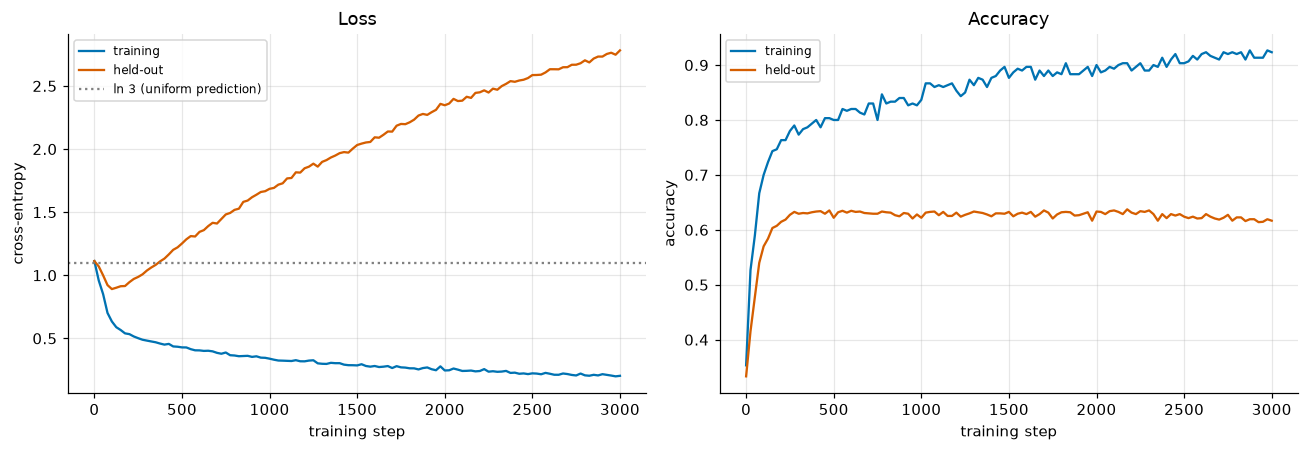

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(hist_t[:, 0], hist_t[:, 1], color=COLORS[0], label="training")
ax1.plot(hist_t[:, 0], hist_t[:, 3], color=COLORS[1], label="held-out")
ax1.axhline(math.log(3), color="gray", ls=":", label="ln 3 (uniform prediction)")
ax1.set_xlabel("training step")
ax1.set_ylabel("cross-entropy")
ax1.set_title("Loss")
ax1.legend(fontsize=8)
ax2.plot(hist_t[:, 0], hist_t[:, 2], color=COLORS[0], label="training")
ax2.plot(hist_t[:, 0], hist_t[:, 4], color=COLORS[1], label="held-out")
ax2.set_xlabel("training step")
ax2.set_ylabel("accuracy")
ax2.set_title("Accuracy")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

The training loss falls throughout and training accuracy keeps creeping up (0.78 at step 250, 0.92 at step 3000). On held-out data the two curves part ways: accuracy reaches its plateau of about 0.62–0.63 by step 250 and stays flat. The held-out loss bottoms out at about 0.9 near step 100, then **climbs**: it passes $\ln 3$ (the loss of a uniform guess) around step 350 and reaches 2.8 by step 3000 — worse than knowing nothing, by this measure, while the accuracy is unchanged. The model's predicted *classes* on new points hardly change; what changes is how **confident** it is in them. As it fits the training points ever more tightly, its logits grow, and on the held-out points it gets wrong it is now very confidently wrong — and cross-entropy charges $-\ln p_y$, which is large when $p_y$ is tiny. (This is overfitting, the subject of notebook 22.)

### Same accuracy, different loss

Accuracy only looks at $\arg\max_k z_k$. Multiplying all logits by a positive constant $1/T$ (dividing by a **temperature** $T$, notebook 10) does not change any arg-max, so it leaves accuracy exactly unchanged — but it changes every probability, and so the cross-entropy:

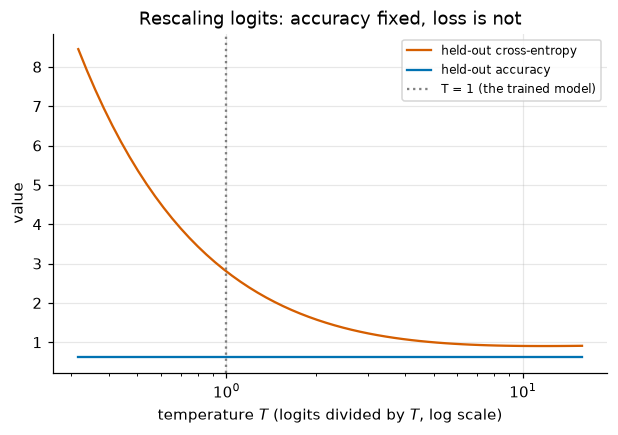

accuracy is the same for every T: True (0.622)
held-out CE at T = 1: 2.799; minimum 0.904 at T ≈ 11.4


In [41]:
with torch.no_grad():
    Z_ho_final = spiral_net(X_ho)                          # (1500, 3) final held-out logits
temps = torch.logspace(-0.5, 1.2, 60)
ce_by_T = torch.stack([F.cross_entropy(Z_ho_final / T_, y_ho) for T_ in temps])
acc_by_T = torch.stack([((Z_ho_final / T_).argmax(1) == y_ho).float().mean() for T_ in temps])
best_T = temps[ce_by_T.argmin()].item()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogx(temps, ce_by_T, color=COLORS[1], label="held-out cross-entropy")
ax.semilogx(temps, acc_by_T, color=COLORS[0], label="held-out accuracy")
ax.axvline(1.0, color="gray", ls=":", label="T = 1 (the trained model)")
ax.set_xlabel("temperature $T$ (logits divided by $T$, log scale)")
ax.set_ylabel("value")
ax.set_title("Rescaling logits: accuracy fixed, loss is not")
ax.legend(fontsize=8)
plt.show()
print(f"accuracy is the same for every T: {bool((acc_by_T == acc_by_T[0]).all())} ({acc_by_T[0].item():.3f})")
print(f"held-out CE at T = 1: {F.cross_entropy(Z_ho_final, y_ho).item():.3f}; minimum {ce_by_T.min().item():.3f} at T ≈ {best_T:.1f}")

Every temperature gives a model with **identical** held-out accuracy, and their cross-entropies differ several-fold; the best temperature is well above 1, confirming that the trained model is overconfident. Choosing $T$ on held-out data is called **temperature scaling** (Guo et al., 2017), a standard way to repair the calibration of a trained classifier; notebook 25 covers calibration in detail.

### Why train on the loss, and report the metric?

- **We cannot train on accuracy.** Accuracy is a step function of the parameters: a small change of the weights almost never changes any arg-max, so its gradient is zero almost everywhere (the same reason the step unit could not be trained, notebooks 07 and 11). Cross-entropy is smooth and its gradient says which way to move.
- **Cross-entropy rewards honest probabilities.** For a single example whose label is drawn from a true distribution $\mathbf q$, the expected loss $-\sum_k q_k\ln p_k = H(\mathbf q) + \mathrm{KL}(\mathbf q\,\|\,\mathbf p)$ is minimized exactly at $\mathbf p = \mathbf q$ (notebook 04). A loss with this property is called a *proper scoring rule*. Accuracy cannot tell a 51% guess from a 99% one.
- **We report the metric** because it is what the user of the model cares about — the fraction of correct answers, or the precision on a rare class (notebook 25). A loss value like "0.41" means little to anyone else.

The two answer different questions, so track both: a falling loss with a flat metric (or the other way round) is information, not a contradiction.

## Exercises

### Exercise 1 (modify): the Huber threshold and outliers

The cell below fits a line $\hat y = wx + b$ by full-batch gradient descent (from zero, $\eta = 0.1$, 3000 steps) to 100 points from $y = 2x - 1$ plus Gaussian noise (std 0.3), with 8 of them turned into outliers ($y$ raised by 15). It compares MSE, MAE and Huber with several thresholds $\delta$, and prints $(w, b)$ after 100 and after 3000 steps, and the final gradient norm.

1. Run it. How do $w$ and $b$ change as $\delta$ goes from 0.1 to 30? Which values of $\delta$ behave like MAE, and which like MSE? Explain with the gradient $\operatorname{clamp}(r, -\delta, \delta)$.
2. Look at the parameters after 100 steps and at the final gradient norms. Which fit is slowest at the start, and which one never reaches a point where the gradient vanishes? Explain both from the shape of the gradient.
3. Change `outlier_shift` to 3 (outliers only about ten noise standard deviations away). Which $\delta$ now gives the best fit, and why? What would you choose for $\delta$ in general, in terms of the noise level?

Answer in the markdown cell below.

<details>
<summary><b>💡 Hint</b></summary>

A point's gradient on $(w, b)$ is $\operatorname{clamp}(r_i, -\delta, \delta)\cdot(x_i, 1)$ (times $1/N$). An outlier whose residual is far beyond $\delta$ pushes with only $\delta$, the same as a good point that is just past the threshold. If $\delta$ is smaller than the typical *noise* residual, even good points are in the linear zone and the fit behaves like MAE. Gradient-descent speed near the optimum depends on how many points are in the quadratic zone.

</details>

MSE           : after 100 steps w =  2.336, b =  0.215 | after 3000: w =  2.336, b =  0.215, gradient norm 8.7e-07
MAE           : after 100 steps w =  1.958, b = -0.948 | after 3000: w =  1.958, b = -0.948, gradient norm 2.0e-02


Huber δ = 0.1 : after 100 steps w =  0.901, b = -0.206 | after 3000: w =  1.962, b = -0.941, gradient norm 6.2e-07


Huber δ = 0.3 : after 100 steps w =  1.949, b = -0.899 | after 3000: w =  1.960, b = -0.939, gradient norm 6.1e-07
Huber δ = 1.0 : after 100 steps w =  1.983, b = -0.887 | after 3000: w =  1.983, b = -0.887, gradient norm 6.0e-07


Huber δ = 3.0 : after 100 steps w =  2.042, b = -0.708 | after 3000: w =  2.042, b = -0.708, gradient norm 9.3e-07


Huber δ = 30.0: after 100 steps w =  2.336, b =  0.215 | after 3000: w =  2.336, b =  0.215, gradient norm 1.1e-06


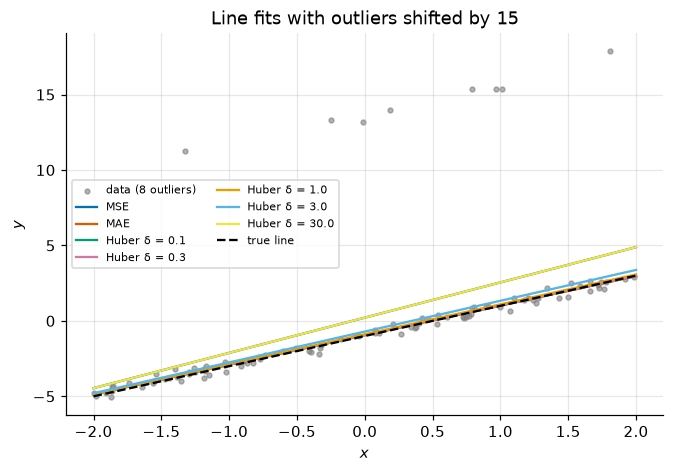

In [42]:
outlier_shift = 15.0
gen = torch.Generator().manual_seed(0)
x_h = 4 * torch.rand(100, generator=gen) - 2                  # (100,)
y_h = 2 * x_h - 1 + 0.3 * torch.randn(100, generator=gen)     # (100,)
y_h[torch.arange(0, 100, 13)] += outlier_shift               # 8 outliers

losses_ex1 = {"MSE": lambda r: (r ** 2).mean(), "MAE": lambda r: r.abs().mean()}
for d in [0.1, 0.3, 1.0, 3.0, 30.0]:
    losses_ex1[f"Huber δ = {d}"] = lambda r, d=d: F.huber_loss(r, torch.zeros_like(r), delta=d)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x_h, y_h, s=10, color="gray", alpha=0.6, label="data (8 outliers)")
xs_line = torch.linspace(-2, 2, 2)
for k, (name, loss_of_residual) in enumerate(losses_ex1.items()):
    w_h = torch.zeros((), requires_grad=True)
    b_h = torch.zeros((), requires_grad=True)
    for step in range(3000):
        loss = loss_of_residual(w_h * x_h + b_h - y_h)
        gw, gb = torch.autograd.grad(loss, [w_h, b_h])
        with torch.no_grad():
            w_h -= 0.1 * gw
            b_h -= 0.1 * gb
        if step == 99:
            early = (w_h.item(), b_h.item())
    gw, gb = torch.autograd.grad(loss_of_residual(w_h * x_h + b_h - y_h), [w_h, b_h])
    print(f"{name:14s}: after 100 steps w = {early[0]:6.3f}, b = {early[1]:6.3f} | after 3000: w = {w_h.item():6.3f}, "
          f"b = {b_h.item():6.3f}, gradient norm {math.hypot(gw.item(), gb.item()):.1e}")
    ax.plot(xs_line, (w_h * xs_line + b_h).detach(), color=COLORS[k % len(COLORS)], label=name)
ax.plot(xs_line, 2 * xs_line - 1, color="k", ls="--", label="true line")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title(f"Line fits with outliers shifted by {outlier_shift:g}")
ax.legend(fontsize=7, ncol=2)
plt.show()

*Your answer:*

### Exercise 2 (implement): label smoothing from scratch

Write `label_smoothing_cross_entropy(logits, y, eps)` for logits of shape `(N, K)`, integer targets of shape `(N,)` and a smoothing $\varepsilon \in [0, 1]$. It must return the mean over the batch of $-\sum_k q_{ik}\ln p_{ik}$, with $\mathbf p_i = \operatorname{softmax}(\mathbf z_i)$ and $\mathbf q_i$ the smoothed target of Section 3, and match `F.cross_entropy(logits, y, label_smoothing=eps)`. Use `F.log_softmax` for stability; do **not** call `F.cross_entropy` or `F.nll_loss`, and do not build the `(N, K)` target with `F.one_hot` — use the expanded form $(1 - \varepsilon)(-\ln p_{y}) + \frac{\varepsilon}{K}\sum_k(-\ln p_k)$ instead.

<details>
<summary><b>💡 Hint</b></summary>

`logp = F.log_softmax(logits, dim=1)` has shape `(N, K)`. The true-class term is `logp[torch.arange(N), y]` (or `logp.gather(1, y[:, None])[:, 0]`); the uniform term is `logp.mean(dim=1)` (that is $\frac1K\sum_k$). Combine and average over the batch.

</details>

In [ ]:
def label_smoothing_cross_entropy(logits, y, eps):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_gen = torch.Generator().manual_seed(5)
for _N, _K, _eps in [(6, 4, 0.1), (50, 10, 0.0), (32, 3, 0.3), (7, 100, 1.0)]:
    _Z = 3 * torch.randn(_N, _K, dtype=f64, generator=_gen)
    _y = torch.randint(0, _K, (_N,), generator=_gen)
    check_close(label_smoothing_cross_entropy(_Z, _y, _eps), F.cross_entropy(_Z, _y, label_smoothing=_eps),
                f"loss for N={_N}, K={_K}, eps={_eps}", rtol=1e-10, atol=1e-12)
_Z = (500 * torch.randn(5, 6, generator=_gen)).requires_grad_(True)   # huge float32 logits: must stay finite
_y = torch.randint(0, 6, (5,), generator=_gen)
_out = label_smoothing_cross_entropy(_Z, _y, 0.1)
check(bool(torch.isfinite(_out)), f"loss with large logits should be finite, got {_out.item()}")
_g = torch.autograd.grad(_out, _Z)[0]
_Z2 = _Z.detach().clone().requires_grad_(True)
_g_ref = torch.autograd.grad(F.cross_entropy(_Z2, _y, label_smoothing=0.1), _Z2)[0]
check_close(_g, _g_ref, "gradient with large logits", rtol=1e-4, atol=1e-6)
passed("Exercise 2")

### Exercise 3 (debug): a tagger that never predicts two tags

`train_tagger` should train a multilabel classifier: each point in $[-1, 1]^2$ can carry any of four tags, and the function returns the model and the predicted **probability of each tag**, shape `(N, 4)`. The buggy version (in the comments) runs, its loss goes down, and on single-tag points it looks fine — but the exact-match accuracy over all points is poor, and no point ever gets two tags. Find what is wrong and write the corrected function body.

<details>
<summary><b>💡 Hint</b></summary>

Print `P.sum(dim=1)` for the buggy version. What does the loss assume about how many tags an example can have? There is more than one line to change: the loss and the way probabilities are computed for the return value must agree.

</details>

In [ ]:
gen = torch.Generator().manual_seed(1)
X_tag = 2 * torch.rand(1500, 2, generator=gen) - 1                       # (N, 2)
Y_tag = torch.stack([X_tag[:, 0] > 0.3,                                  # (N, 4) multi-hot float tags
                     X_tag[:, 1] < -0.2,
                     X_tag[:, 0] * X_tag[:, 1] > 0,
                     (X_tag ** 2).sum(1) > 0.6], dim=1).float()


def train_tagger(X, Y, steps=1500, lr=1e-2):
    """Train a multilabel classifier on X (N, 2), Y (N, 4) float multi-hot. Returns (model, P) with P (N, 4)."""
    model = make_mlp(2, 4, seed=0, width=64)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    # Buggy version:
    #     for _ in range(steps):
    #         loss = F.cross_entropy(model(X), Y)
    #         opt.zero_grad()
    #         loss.backward()
    #         opt.step()
    #     with torch.no_grad():
    #         P = torch.softmax(model(X), dim=1)
    #     return model, P
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
_model, _P = train_tagger(X_tag, Y_tag)
check_shape(_P, (1500, 4), "P")
check(bool(((_P >= 0) & (_P <= 1)).all()), "P should contain probabilities in [0, 1]")
_exact = ((_P > 0.5).float() == Y_tag).all(dim=1).float().mean().item()
_multi = Y_tag.sum(1) >= 2
_exact_multi = ((_P > 0.5).float() == Y_tag).all(dim=1)[_multi].float().mean().item()
check(_exact > 0.9, f"exact-match accuracy is {_exact:.3f}; a correct multilabel model reaches above 0.9 on this data")
check(_exact_multi > 0.85, f"exact-match accuracy on points with 2+ tags is {_exact_multi:.3f}; expected above 0.85")
passed("Exercise 3")

For comparison, the buggy version run directly:

In [47]:
def train_tagger_buggy(X, Y, steps=1500, lr=1e-2):
    model = make_mlp(2, 4, seed=0, width=64)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(steps):
        loss = F.cross_entropy(model(X), Y)
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        P = torch.softmax(model(X), dim=1)
    return model, P


_, P_bug = train_tagger_buggy(X_tag, Y_tag)
exact_bug = ((P_bug > 0.5).float() == Y_tag).all(dim=1)
print("tags per point, counts for 0/1/2/3/4:", torch.bincount(Y_tag.sum(1).long(), minlength=5).tolist())
print(f"buggy: exact-match accuracy {exact_bug.float().mean().item():.3f}; on points with exactly 1 tag "
      f"{exact_bug[Y_tag.sum(1) == 1].float().mean().item():.3f}; with 2+ tags {exact_bug[Y_tag.sum(1) >= 2].float().mean().item():.3f}")
print(f"buggy: P.sum(dim=1) ranges from {P_bug.sum(1).min().item():.4f} to {P_bug.sum(1).max().item():.4f}")

tags per point, counts for 0/1/2/3/4: [186, 422, 394, 498, 0]
buggy: exact-match accuracy 0.281; on points with exactly 1 tag 1.000; with 2+ tags 0.000
buggy: P.sum(dim=1) ranges from 1.0000 to 1.0000


### Exercise 4 (investigate): what do class weights trade?

Imbalanced data: 950 points of class 0 and 50 of class 1, from overlapping blobs (std 1.0). The scaffold trains a small MLP with plain cross-entropy and with class weights `weight = (1, 19)` (the "balanced" choice $w_k \propto 1/n_k$), for 5 seeds each (each seed draws a new training set and initialization). It evaluates on a large held-out set drawn from the same two blobs and reports:

- the accuracy on class 0 and on class 1 separately (the fraction of each class predicted correctly — the *recall* of each class, notebook 25);
- the overall accuracy on held-out data **with the same 95/5 imbalance** as training, and **balanced accuracy**, the average of the two per-class accuracies.

Run it and answer in the markdown cell:

1. What does weighting do to each per-class accuracy, and to the overall accuracy? Are the differences larger than the seed-to-seed spread?
2. Which model would you deploy to screen for a rare disease (class 1), and which to minimize the total number of mistakes? Explain using Section 3's result about what weights do to the predicted class proportions.
3. Optional: try `weight = (1, 5)`. Where does it land?

<details>
<summary><b>💡 Hint</b></summary>

Section 3 showed that weights change the class proportions the model believes in: with balanced weights it acts as if the classes were 50/50, so it moves the boundary toward the majority class. Overall accuracy on 95/5 data is $0.95\,a_0 + 0.05\,a_1$ — which term dominates?

</details>

plain            : class-0 acc 0.989 ± 0.004 | class-1 acc 0.620 ± 0.040 | overall (95/5) 0.971 ± 0.005 | balanced 0.805 ± 0.022


weight = (1, 19) : class-0 acc 0.949 ± 0.012 | class-1 acc 0.796 ± 0.050 | overall (95/5) 0.941 ± 0.010 | balanced 0.872 ± 0.021


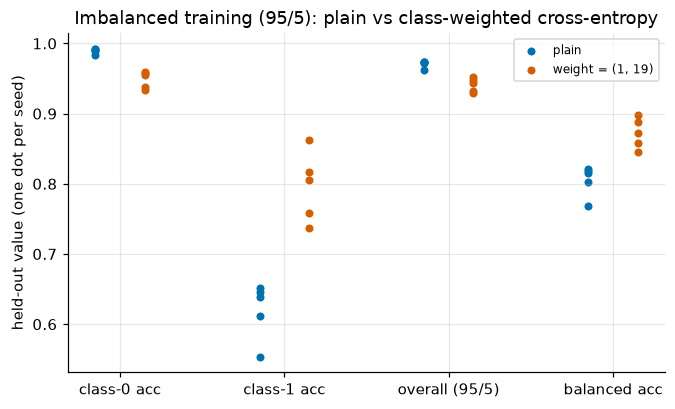

In [48]:
def imbalance_run(seed, class_weight):
    X0, y0 = make_blobs(n=950, std=1.0, seed=seed)             # 950 per class; keep only 50 of class 1
    keep = torch.cat([torch.arange(950), 950 + torch.arange(50)])
    X_tr_i, y_tr_i = X0[keep], y0[keep]                        # (1000, 2), (1000,) — 95% class 0
    X_te, y_te = make_blobs(n=5000, std=1.0, seed=1000 + seed) # held-out, balanced: 5000 of each class
    model = make_mlp(2, 2, seed=seed, width=16)
    train_full_batch(model, lambda Z: F.cross_entropy(Z, y_tr_i, weight=class_weight), X_tr_i, steps=500)
    with torch.no_grad():
        pred = model(X_te).argmax(1)
    a0 = (pred[y_te == 0] == 0).float().mean().item()
    a1 = (pred[y_te == 1] == 1).float().mean().item()
    return a0, a1, 0.95 * a0 + 0.05 * a1, (a0 + a1) / 2         # overall accuracy at the 95/5 mix, balanced accuracy


results_ex4 = {}
for name, cw in [("plain", None), ("weight = (1, 19)", torch.tensor([1.0, 19.0]))]:
    results_ex4[name] = torch.tensor([imbalance_run(s, cw) for s in range(5)])   # (seeds, 4)
    m, sd = results_ex4[name].mean(0), results_ex4[name].std(0)
    print(f"{name:17s}: class-0 acc {m[0]:.3f} ± {sd[0]:.3f} | class-1 acc {m[1]:.3f} ± {sd[1]:.3f} | "
          f"overall (95/5) {m[2]:.3f} ± {sd[2]:.3f} | balanced {m[3]:.3f} ± {sd[3]:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
labels_ex4 = ["class-0 acc", "class-1 acc", "overall (95/5)", "balanced acc"]
for k, (name, res) in enumerate(results_ex4.items()):
    for j in range(4):
        ax.scatter([j + 0.15 * (2 * k - 1)] * len(res), res[:, j], color=COLORS[k], s=18, label=name if j == 0 else None)
ax.set_xticks(range(4))
ax.set_xticklabels(labels_ex4)
ax.set_ylabel("held-out value (one dot per seed)")
ax.set_title("Imbalanced training (95/5): plain vs class-weighted cross-entropy")
ax.legend(fontsize=8)
plt.show()

*Your conclusion:*

## Summary and what's next

- **A loss is a probabilistic model of the targets.** Choose a distribution $p(y \mid \mathbf o)$, let the network output its unconstrained parameters (logits, a mean and a log-variance, a log-rate), and minimize the average NLL. Gaussian → MSE, Laplace → MAE, Bernoulli → BCE, categorical → cross-entropy, Poisson → $e^s - ys$, $K$ independent Bernoullis → multilabel BCE. The gradient with respect to the natural output is usually "prediction minus target".
- **Huber** is quadratic for $|r| \le \delta$ and linear beyond; its gradient is $\operatorname{clamp}(r, -\delta, \delta)$, so outliers push with at most $\delta$. `F.smooth_l1_loss` with $\beta = \delta$ equals Huber divided by $\delta$.
- The **Gaussian NLL with a predicted variance** makes a network report its own noise level: the optimum sets $\sigma^2$ to the local mean squared residual. Predict $\ln\sigma^2$ to keep the variance positive.
- **`F.cross_entropy`**: class scores in dimension 1 (`(N, K, d…)`; a wrong layout errors only when the sizes differ); `ignore_index` excludes targets from both the sum and the count; `weight=` gives a weighted mean and shifts the model's belief about class proportions to $w_k n_k / \sum_j w_j n_j$; `label_smoothing=ε` trains towards $(1 - \varepsilon)\,\text{one-hot} + \varepsilon/K$, whose minimum loss is the entropy $H(\mathbf q) > 0$ at finite logits; float `(N, K)` targets are soft labels.
- **Multilabel** targets need per-label sigmoids and BCE: softmax forces the labels to compete and cannot express "none" or "several". `pos_weight` shifts each label's predicted probability up, to $p\pi / (p\pi + 1 - \pi)$ for a constant predictor.
- **Reductions**: `sum` multiplies the gradient by $N$ and so SGD's effective learning rate (Adam hardly notices); `none` gives per-example losses for masks and weights. "Mean" divides by $\sum_i w_{y_i}$ with class weights and integer targets, by $N$ with soft targets, by the number of kept targets with `ignore_index`, and by $N\cdot K$ for elementwise BCE.
- **Interfaces**: logits in, never softmax-then-log; `F.nll_loss` wants log-probabilities; int64 class indices for cross-entropy, float targets of the **same shape** for BCE and MSE. Many mistakes raise readable errors; the dangerous ones are silent.
- **Loss ≠ metric**: we train on a smooth loss that rewards honest probabilities, and report the metric people care about. Held-out loss can rise while held-out accuracy stays flat (overconfidence); rescaling logits changes the loss and not the accuracy.

We now know *what* to minimize. Whether gradient descent can minimize it efficiently in a deep network depends heavily on where it starts: with a poor initialization, activations and gradients shrink or blow up from layer to layer and training stalls before the loss can do its job. Notebook 18 derives how the variance of activations propagates through layers and where the Xavier and Kaiming initializations come from.